# Avance 4. Modelos alternativos
## Sistema de conteo de productos Vetlife — Equipo 32

**Fecha:** 25 de octubre de 2026
**Datos:** 44 fotografías de anaquel anotadas en Label Studio, 676 productos individuales, 44 clases
**Objetivo:** explorar una gama diversa de algoritmos para **identificar el producto de cada caja** (la etapa que luego alimenta el conteo), compararlos con un mismo protocolo, **ajustar los dos mejores** y **elegir un modelo individual final**.

> **Punto de partida (Avance 3).** El baseline (regresión logística sobre 92 características de color, forma y textura) obtuvo un macro-F1 de ≈ 0.35 en validación cruzada y de 0.169 en una prueba fija de 10 fotos; identificaba la marca el 92.5 % de las veces, pero el producto exacto solo el 42.8 %. Los errores se concentraban entre presentaciones casi idénticas de una misma línea (dosis, número de tabletas). Este avance busca saber **si otro algoritmo, otra representación de la imagen o un mejor ajuste cierran esa brecha**, y a qué costo.

## 1. Qué pide el avance y dónde se responde

| Requisito | Dónde se responde |
|---|---|
| ≥ 6 modelos **individuales** (no ensambles) con algoritmos variados | §5: 8 algoritmos (regresión logística, SVM lineal, SVM RBF, k vecinos, árbol de decisión, Naive Bayes, análisis discriminante lineal, red neuronal MLP). Se excluyen bosques aleatorios y *boosting* por ser ensambles. |
| Comparar rendimiento: métrica principal + ≥ 2 métricas + tiempos | §6: macro-F1 (principal), *balanced accuracy*, top-3 y exactitud por línea, además del tiempo de entrenamiento |
| Seleccionar los dos mejores | §7 |
| Ajustar los dos mejores | §8: búsqueda aleatoria de hiperparámetros con validación cruzada agrupada por foto |
| Elegir el modelo individual final | §9–§10: métricas, incertidumbre, costo, interpretabilidad y despliegue |
| Declaración de uso de IA | Última sección |

**Representaciones.** Además de comparar algoritmos, se compara **qué se le da al algoritmo**: (A) las 92 características diseñadas a mano del Avance 3, (B) *embeddings* de 960 dimensiones de una red convolucional preentrenada (MobileNetV3-Large, ImageNet) usada solo como extractor de características, y (C) la concatenación de ambas. Una red convolucional afinada de extremo a extremo requiere GPU y queda como siguiente paso; aquí se usa congelada.

## 2. Dependencias y datos

Se usa Python, NumPy, pandas, Pillow, scikit-image, scikit-learn, PyTorch/torchvision (solo para extraer *embeddings*), Matplotlib y seaborn. El notebook busca localmente las fotografías (`label_data/`) y las exportaciones de Label Studio; **no se distribuyen en el repositorio**. Las imágenes que aparecen en las salidas están reducidas a baja resolución para ilustrar el caso de uso.

In [1]:
import os
os.environ["PYTHONWARNINGS"] = "ignore"      # los procesos paralelos de scikit-learn heredan el filtro y no ensucian las salidas
from pathlib import Path
import json, urllib.parse, time, platform, warnings, io, pickle
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageDraw, ImageOps
from IPython.display import display
from scipy.ndimage import laplace
from scipy.stats import loguniform, uniform, randint
from skimage.color import rgb2hsv
from skimage.feature import hog
from skimage.filters import sobel
from skimage.measure import shannon_entropy

import sklearn, torch, torchvision, joblib
from torchvision import transforms as T
from torchvision.models import (mobilenet_v3_large, MobileNet_V3_Large_Weights, convnext_tiny, ConvNeXt_Tiny_Weights,
                                resnet50, ResNet50_Weights, efficientnet_b0, EfficientNet_B0_Weights)
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC, LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.model_selection import StratifiedGroupKFold, cross_validate, RandomizedSearchCV
from sklearn.metrics import f1_score, accuracy_score, balanced_accuracy_score, make_scorer, confusion_matrix

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 160)
SEED = 42
print(f"Python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | scikit-learn {sklearn.__version__} | torch {torch.__version__}")

Python 3.9.6 | numpy 2.0.2 | pandas 2.3.3 | scikit-learn 1.6.1 | torch 2.8.0


In [2]:
# Búsqueda de datos: funciona al ejecutar desde la raíz del proyecto, desde avances/ o desde Zproyect_Main/.
BASES = [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent]
def find_dir(options):
    for base in BASES:
        for rel in options:
            if (base / rel).is_dir():
                return (base / rel).resolve()
    return None

PHOTO_DIR  = find_dir(["label_data", "Vetlife_Proyecto/label_data"])
EXPORT_DIR = find_dir(["Zproyect_Main/01_datos/exportaciones_label_studio", "01_datos/exportaciones_label_studio",
                       "Vetlife_Proyecto/Zproyect_Main/01_datos/exportaciones_label_studio"])
REF_DIR    = find_dir(["Zproyect_Main/Fotos_de_referencia", "Fotos_de_referencia", "Vetlife_Proyecto/Zproyect_Main/Fotos_de_referencia"])
if PHOTO_DIR is None or EXPORT_DIR is None:
    raise FileNotFoundError("Colocar label_data/ y las exportaciones de Label Studio junto al proyecto (ver README).")
print("Fotos anotadas  :", PHOTO_DIR.name, "| Exportaciones:", [p.name for p in sorted(EXPORT_DIR.iterdir()) if p.is_dir()])
print("Fotos de referencia:", REF_DIR.name if REF_DIR else "no disponibles")

Fotos anotadas  : label_data | Exportaciones: ['2026-10-15', '2026-10-17']
Fotos de referencia: Fotos_de_referencia


### 2.1 Imágenes de referencia: el escenario real

Fotografías sin anotar que ilustran las condiciones de uso: anaqueles con muchas cajas casi idénticas, apiladas y con reflejos.

9 fotografías de referencia


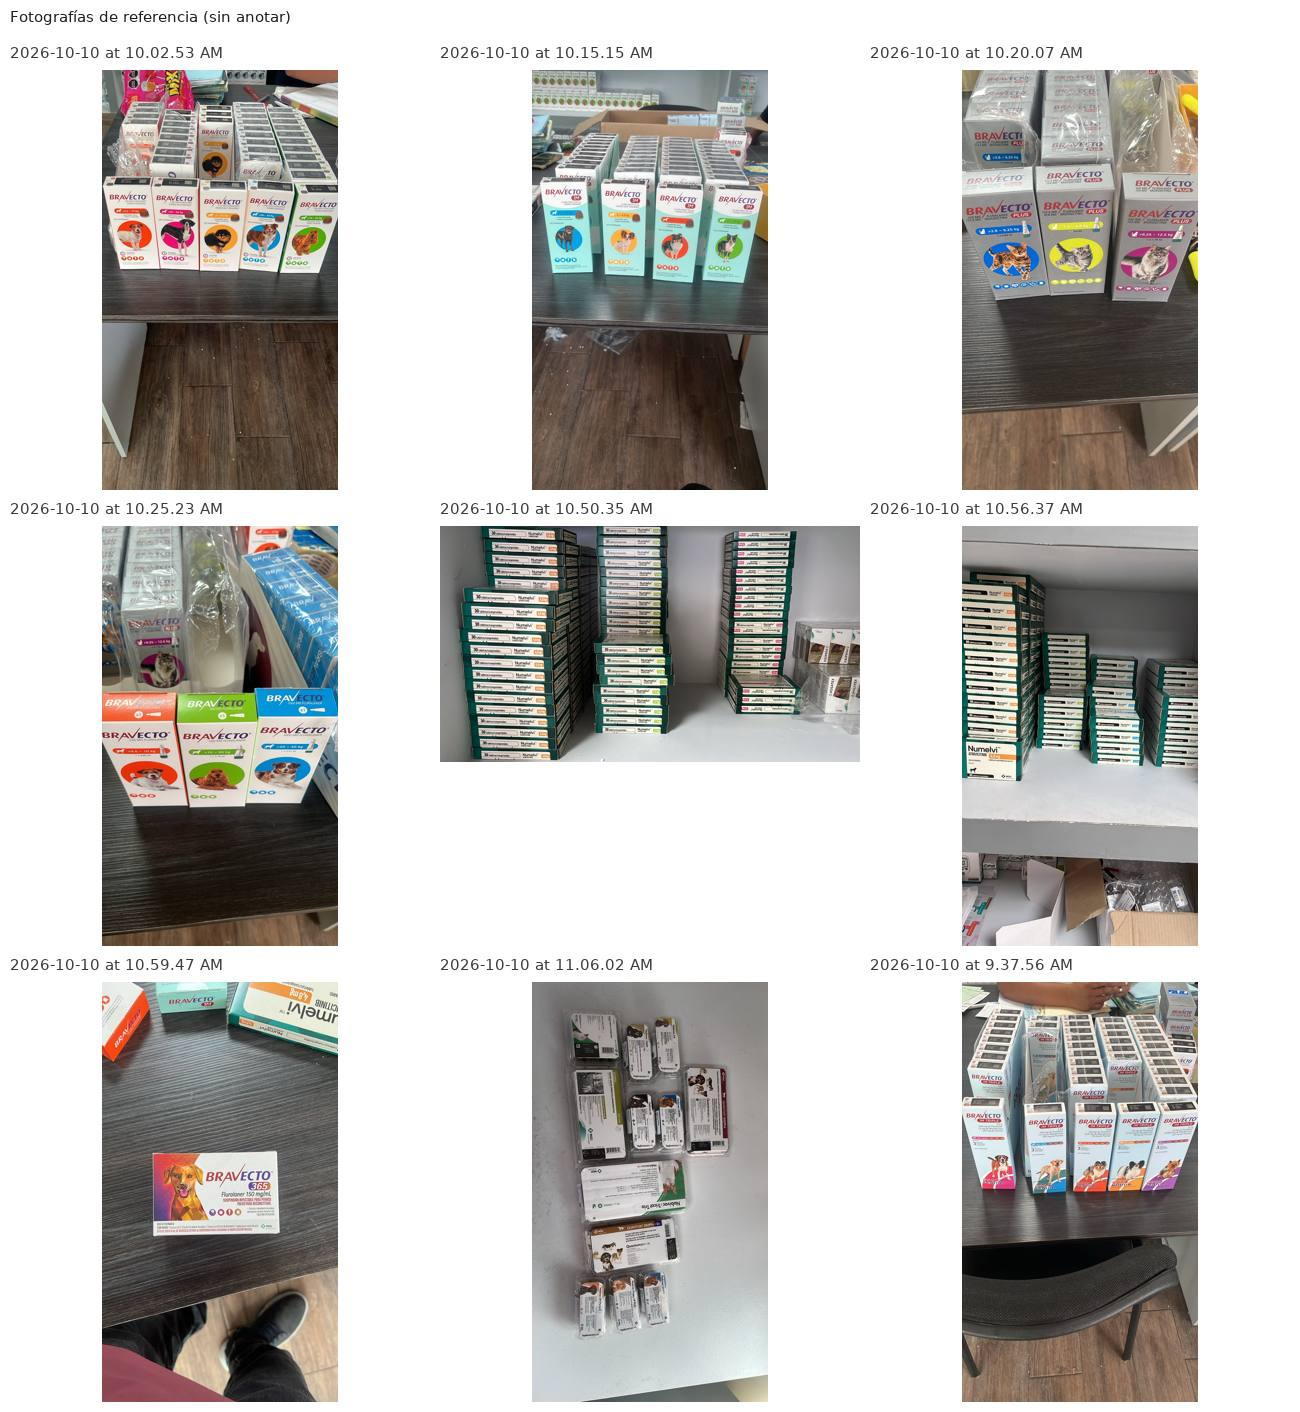

In [3]:
import io
from IPython.display import Image as IPyImage
from PIL import ImageFont
import matplotlib
try:   # DejaVu Sans (incluida con Matplotlib) trae acentos; la fuente por defecto de Pillow no siempre
    FONT = ImageFont.truetype(str(Path(matplotlib.get_data_path()) / "fonts" / "ttf" / "DejaVuSans.ttf"), 15)
except Exception:
    FONT = None

def show_mosaic(tiles, captions, cols=3, cell=420, title=None, quality=72):
    """Mosaico de imágenes como un solo JPEG de baja resolución (ilustra el escenario, no el detalle de la caja; pesa poco)."""
    rows, pad, head = (len(tiles) + cols - 1) // cols, 10, 26
    top = 34 if title else 0
    canvas = Image.new("RGB", (cols * (cell + pad) + pad, top + rows * (cell + head + pad) + pad), "white")
    d = ImageDraw.Draw(canvas)
    if title: d.text((pad, 8), title, fill=(30, 30, 30), font=FONT)
    for k, (im, cap) in enumerate(zip(tiles, captions)):
        im = im.copy(); im.thumbnail((cell, cell))
        x, y = pad + (k % cols) * (cell + pad), top + pad + (k // cols) * (cell + head + pad)
        d.text((x, y), cap, fill=(60, 60, 60), font=FONT)
        canvas.paste(im, (x + (cell - im.width) // 2, y + head))
    buf = io.BytesIO(); canvas.save(buf, "JPEG", quality=quality)
    display(IPyImage(data=buf.getvalue(), format="jpeg"))

def show_grid(paths, cols=3, max_side=420, title=None):
    tiles, caps = [], []
    for p in paths:
        with Image.open(p) as im:
            tiles.append(ImageOps.exif_transpose(im).convert("RGB"))
        caps.append(Path(p).stem.replace("WhatsApp Image ", ""))
    show_mosaic(tiles, caps, cols=cols, cell=max_side, title=title)

if REF_DIR:
    ref_paths = sorted(p for p in REF_DIR.iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png"})
    print(f"{len(ref_paths)} fotografías de referencia")
    show_grid(ref_paths, cols=3, title="Fotografías de referencia (sin anotar)")

### 2.2 Anotaciones y características por producto

Se reutiliza el procesamiento del Avance 3: se leen todas las exportaciones de Label Studio, se agrupan los polígonos por fotografía (los ids de tarea se repiten entre exportaciones), se descartan duplicados y cada polígono se recorta de la foto. Cada fila es **un producto con su etiqueta real**.

In [4]:
def box_iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0])); iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union > 0 else 0.0

def load_annotations(export_dir, photo_dir):
    index = {}
    for p in photo_dir.rglob("*"):
        if p.is_file(): index.setdefault(p.name.casefold(), []).append(p)
    photos, unresolved, ignored = {}, 0, 0
    for export in sorted(export_dir.rglob("*.json")):
        tasks = json.loads(export.read_text(encoding="utf-8-sig"))
        tasks = tasks.get("tasks", [tasks]) if isinstance(tasks, dict) else tasks
        for task in tasks:
            ref = str((task.get("data") or {}).get("image", "")).replace("\\", "/").replace("%5C", "/")
            rel = urllib.parse.parse_qs(urllib.parse.urlparse(ref).query).get("d", [urllib.parse.urlparse(ref).path])[0]
            matches = index.get(Path(urllib.parse.unquote(rel)).name.casefold(), [])
            if len(matches) != 1:
                unresolved += 1; continue
            entry = photos.setdefault(matches[0], {"polys": [], "seen": set()})
            for ann in task.get("annotations", []):
                if ann.get("was_cancelled"): continue
                for res in ann.get("result", []):
                    val = res.get("value") or {}
                    if res.get("type") != "polygonlabels" or not val.get("polygonlabels") or len(val.get("points", [])) < 3:
                        ignored += 1; continue
                    pts = [(float(x), float(y)) for x, y in val["points"]]
                    key = (val["polygonlabels"][0], tuple((round(x, 3), round(y, 3)) for x, y in pts))
                    if key in entry["seen"]: continue
                    entry["seen"].add(key)
                    entry["polys"].append((val["polygonlabels"][0].strip(), pts, int(res.get("image_rotation") or 0)))
    return photos, unresolved, ignored

photos, unresolved, ignored = load_annotations(EXPORT_DIR, PHOTO_DIR)
print(f"Fotos con anotaciones: {len(photos)} | tareas sin foto: {unresolved} | resultados ignorados (no polígonos): {ignored}")

Fotos con anotaciones: 44 | tareas sin foto: 0 | resultados ignorados (no polígonos): 1

In [5]:
FEATURE_GROUPS = {"geo_": "Geometría", "col_": "Color global", "hue_": "Matiz", "lay_": "Distribución de color 3×3",
                  "tex_": "Textura", "hog_": "Formas (HOG)"}

def crop_features(img, pts_pct, W, H):
    poly = [(x * W / 100, y * H / 100) for x, y in pts_pct]
    xs, ys = zip(*poly)
    x1, y1, x2, y2 = max(0, int(min(xs))), max(0, int(min(ys))), min(W, int(np.ceil(max(xs)))), min(H, int(np.ceil(max(ys))))
    bw, bh = x2 - x1, y2 - y1
    if bw < 8 or bh < 8:
        return None, None
    crop = img.crop((x1, y1, x2, y2))
    m = Image.new("L", (bw, bh), 0); ImageDraw.Draw(m).polygon([(x - x1, y - y1) for x, y in poly], fill=1)
    mask = np.asarray(m, bool)
    if mask.sum() < 30:
        return None, None
    a = np.asarray(crop, np.float32) / 255; hsv = rgb2hsv(a)
    area = 0.5 * abs(sum(poly[i][0] * poly[(i + 1) % len(poly)][1] - poly[(i + 1) % len(poly)][0] * poly[i][1] for i in range(len(poly))))
    f = {"geo_ancho_rel": bw / W, "geo_alto_rel": bh / H, "geo_aspecto": bw / bh, "geo_area_rel": bw * bh / (W * H),
         "geo_cx": (x1 + x2) / 2 / W, "geo_cy": (y1 + y2) / 2 / H, "geo_relleno": min(1, area / (bw * bh))}
    px, hp = a[mask], hsv[mask]
    for i, c in enumerate("rgb"):
        f[f"col_{c}_media"] = px[:, i].mean(); f[f"col_{c}_std"] = px[:, i].std()
    f.update({"col_sat_media": hp[:, 1].mean(), "col_sat_std": hp[:, 1].std(), "col_val_media": hp[:, 2].mean(), "col_val_std": hp[:, 2].std()})
    hh, _ = np.histogram(hp[:, 0], bins=12, range=(0, 1), weights=hp[:, 1] + 1e-6); hh = hh / hh.sum()
    for i, v in enumerate(hh): f[f"hue_{i:02d}"] = v
    filled = np.where(mask[..., None], a, px.mean(0))
    small = np.asarray(Image.fromarray((filled * 255).astype(np.uint8)).resize((48, 48), Image.Resampling.BILINEAR), np.float32) / 255
    for r in range(3):
        for c in range(3):
            blk = small[r * 16:(r + 1) * 16, c * 16:(c + 1) * 16].mean((0, 1))
            for k, n in enumerate("rgb"): f[f"lay_{r}{c}_{n}"] = blk[k]
    g = small.mean(2); e = sobel(g)
    f.update({"tex_borde_media": e.mean(), "tex_borde_densidad": (e > 0.1).mean(), "tex_laplaciano_var": laplace(g).var(), "tex_entropia": shannon_entropy(g)})
    for i, v in enumerate(hog(g, orientations=8, pixels_per_cell=(24, 24), cells_per_block=(1, 1), feature_vector=True)):
        f[f"hog_{i:02d}"] = v
    thumb = crop.copy(); thumb.thumbnail((120, 120))
    return f, thumb

def linea(c):
    for prefix, name in [("Bravecto 1M Triple", "Bravecto 1M Triple"), ("Bravecto 1M", "Bravecto 1M"), ("Bravecto Spot", "Bravecto Spot On"),
                         ("Bravecto Plus", "Bravecto Plus gato"), ("Bravecto 365", "Bravecto 365"), ("Bravecto", "Bravecto por peso"),
                         ("Nobivac", "Nobivac"), ("Numelvi", "Numelvi"), ("Quantum", "Quantum Dog")]:
        if c.startswith(prefix): return name
    return "Otro"
marca = lambda c: c.split()[0].replace("NobivacFeline", "Nobivac")

def embedding_crop(img, pts_pct, W, H, margin=0.10, max_side=448):
    """Recorte rectangular con 10 % de margen, en su proporción original (sin relleno), para la CNN."""
    xs, ys = [x * W / 100 for x, _ in pts_pct], [y * H / 100 for _, y in pts_pct]
    bw, bh = max(xs) - min(xs), max(ys) - min(ys)
    box = (max(0, int(min(xs) - margin * bw)), max(0, int(min(ys) - margin * bh)), min(W, int(max(xs) + margin * bw)), min(H, int(max(ys) + margin * bh)))
    crop = img.crop(box); crop.thumbnail((max_side, max_side))
    return crop

t0 = time.time()
rows, THUMBS, POLYS, EMB_CROPS, FEAT_T = [], [], [], [], []
PHOTO_PATH = {}
for path, entry in sorted(photos.items(), key=lambda kv: str(kv[0]).casefold()):
    with Image.open(path) as src:
        img = ImageOps.exif_transpose(src).convert("RGB")
    img.thumbnail((1600, 1600)); W, H = img.size
    PHOTO_PATH[path.name] = path
    kept = []
    for label, pts, rotation in entry["polys"]:
        if rotation != 0: continue
        xs, ys = [p[0] for p in pts], [p[1] for p in pts]; box = [min(xs), min(ys), max(xs), max(ys)]
        if any(l == label and box_iou(b, box) > 0.9 for l, b in kept): continue
        _t = time.perf_counter(); f, thumb = crop_features(img, pts, W, H); FEAT_T.append(time.perf_counter() - _t)
        if f is None: continue
        kept.append((label, box))
        rows.append({"foto": path.name, "clase": label, "linea": linea(label), "marca": marca(label), **f}); THUMBS.append(thumb); POLYS.append(pts); EMB_CROPS.append(embedding_crop(img, pts, W, H))
df = pd.DataFrame(rows)
FEATURES = [c for c in df.columns if c.startswith(tuple(FEATURE_GROUPS))]
GROUP_OF = {c: next(v for k, v in FEATURE_GROUPS.items() if c.startswith(k)) for c in FEATURES}
print(f"Productos (filas): {len(df)} | fotos: {df.foto.nunique()} | clases: {df.clase.nunique()} | características: {len(FEATURES)} | {time.time() - t0:.0f} s")
print("Valores faltantes:", int(df[FEATURES].isna().sum().sum()), "| infinitos:", int(np.isinf(df[FEATURES].values).sum()))
display(pd.Series(Counter(GROUP_OF.values())).rename("n_características").to_frame())

Productos (filas): 676 | fotos: 44 | clases: 44 | características: 92 | 12 s
Valores faltantes: 0 | infinitos: 0


,n_características
Geometría,7
Color global,10
Matiz,12
Distribución de color 3×3,27
Textura,4
Formas (HOG),32


### 2.3 Los datos: desbalance y similitud entre productos

Clases: 44 | productos por clase: mediana 12, mínimo 1, máximo 62
Clases con menos de 5 ejemplos: 9 | con 1 ejemplo: 1
La clase mayoritaria concentra 9.2% de los productos (referencia para 'accuracy' ingenua)
Productos por foto: mediana 7, mínimo 1, máximo 60


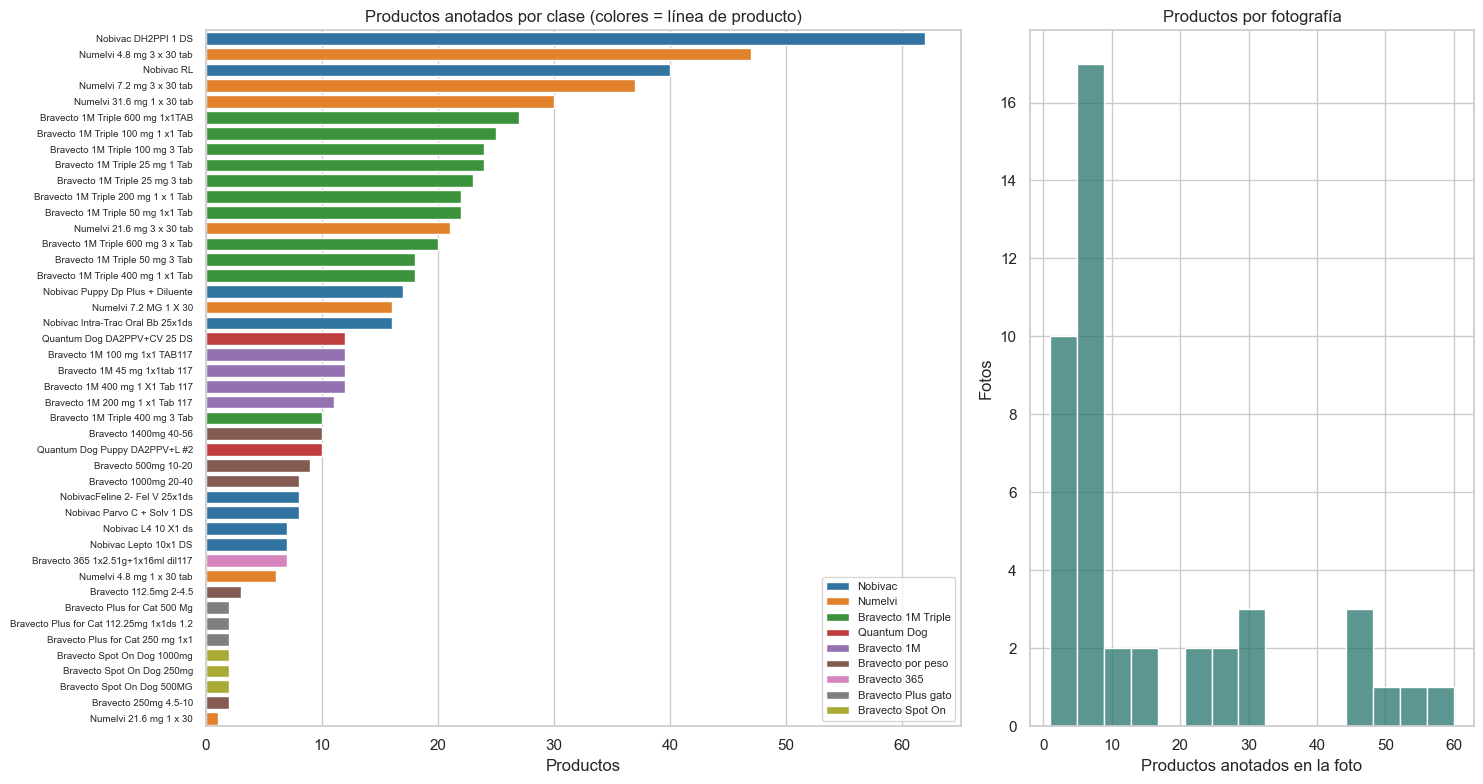

In [6]:
counts = df.clase.value_counts()
print(f"Clases: {len(counts)} | productos por clase: mediana {counts.median():.0f}, mínimo {counts.min()}, máximo {counts.max()}")
print(f"Clases con menos de 5 ejemplos: {(counts < 5).sum()} | con 1 ejemplo: {(counts == 1).sum()}")
print(f"La clase mayoritaria concentra {counts.iloc[0] / len(df):.1%} de los productos (referencia para 'accuracy' ingenua)")
per_photo = df.groupby("foto").size()
print(f"Productos por foto: mediana {per_photo.median():.0f}, mínimo {per_photo.min()}, máximo {per_photo.max()}")

fig, axes = plt.subplots(1, 2, figsize=(15, 8), gridspec_kw={"width_ratios": [1.7, 1]})
order = counts.index
sns.barplot(y=order, x=counts.values, hue=[linea(c) for c in order], dodge=False, ax=axes[0], palette="tab10")
axes[0].set_title("Productos anotados por clase (colores = línea de producto)"); axes[0].set_xlabel("Productos"); axes[0].set_ylabel("")
axes[0].tick_params(axis="y", labelsize=7); axes[0].legend(fontsize=8, loc="lower right")
sns.histplot(per_photo.values, bins=15, color="#26736b", ax=axes[1])
axes[1].set_title("Productos por fotografía"); axes[1].set_xlabel("Productos anotados en la foto"); axes[1].set_ylabel("Fotos")
fig.tight_layout(); plt.show()

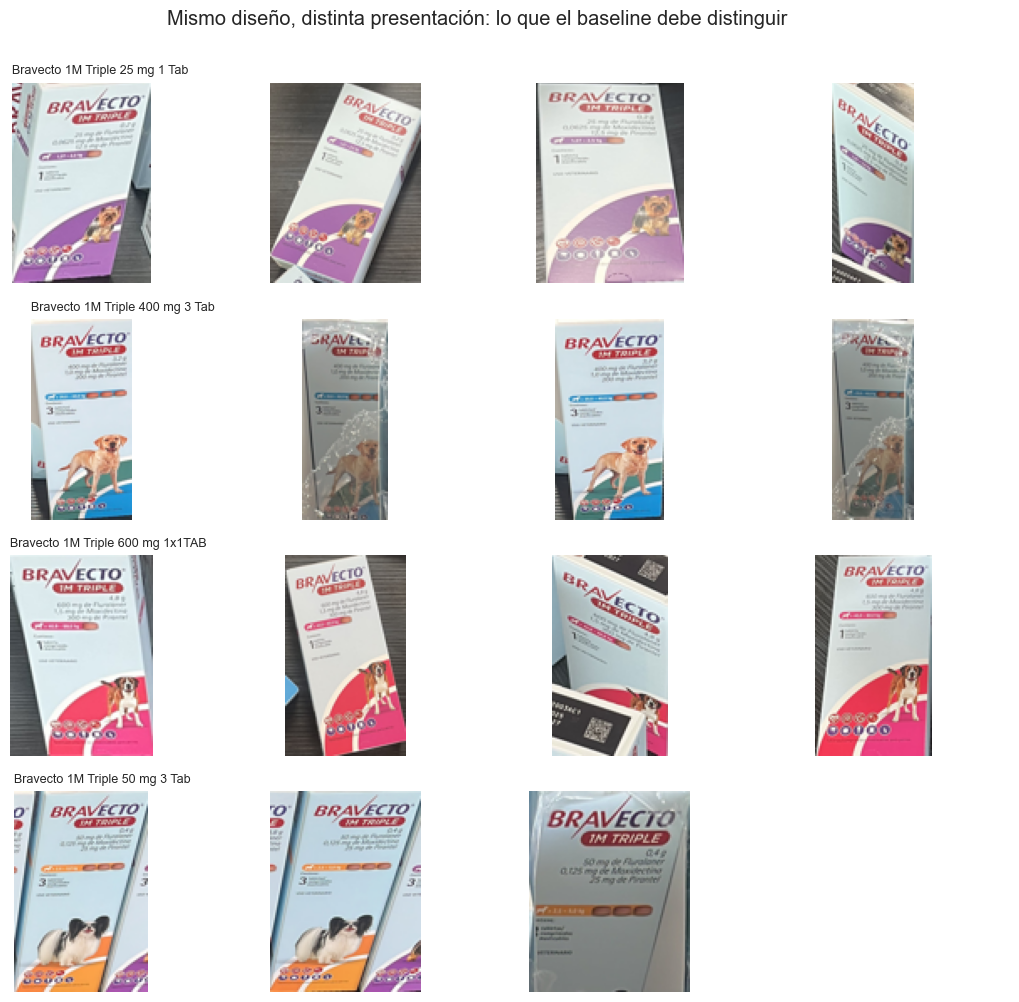

In [7]:
# Cómo se ven los recortes: 4 presentaciones de la misma línea, que difieren solo en dosis / número de tabletas.
# Se muestran frentes de caja (más altas que anchas); las tapas laterales se analizan en la sección 7.1.
front = df.geo_aspecto < 0.8
triple = df[(df.linea == "Bravecto 1M Triple") & front].clase.value_counts()
show_classes = triple[triple >= 3].index[:4].tolist()
fig, axes = plt.subplots(len(show_classes), 4, figsize=(11, 2.5 * len(show_classes)))
for r, cls in enumerate(show_classes):
    idxs = df.index[(df.clase == cls) & front].tolist()[:: max(1, ((df.clase == cls) & front).sum() // 4)][:4]
    for c in range(4):
        ax = axes[r, c]; ax.axis("off")
        if c < len(idxs): ax.imshow(THUMBS[idxs[c]])
        if c == 0: ax.set_title(cls, fontsize=9, loc="left")
fig.suptitle("Mismo diseño, distinta presentación: lo que el baseline debe distinguir", y=1.0)
fig.tight_layout(); plt.show()

## 3. Partición entrenamiento / prueba

Se usa **exactamente la misma partición del Avance 3** (por fotografía, estratificada por clase, semilla 42) para que los resultados sean comparables con el baseline. Los productos de una misma foto comparten luz, ángulo y fondo; separarlos entre entrenamiento y prueba produciría una prueba artificialmente fácil. Todo el ajuste de modelos e hiperparámetros se hace **solo con el conjunto de entrenamiento**; la prueba se evalúa al final, una vez por modelo.

In [8]:
X_A = df[FEATURES].values; y = df.clase.values; groups = df.foto.values
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, test_idx = next(splitter.split(X_A, y, groups))
ytr, gtr, yte, gte = y[train_idx], groups[train_idx], y[test_idx], groups[test_idx]
assert not set(gtr) & set(gte), "una foto no puede estar en ambos conjuntos"

unseen = sorted(set(yte) - set(ytr))
print(f"Entrenamiento: {len(train_idx)} productos / {len(set(gtr))} fotos / {len(set(ytr))} clases")
print(f"Prueba       : {len(test_idx)} productos / {len(set(gte))} fotos / {len(set(yte))} clases")
print(f"Clases de prueba ausentes en entrenamiento: {len(unseen)} ({int(np.isin(yte, unseen).sum())} productos que ningún modelo puede acertar)")
prev = EXPORT_DIR.parent / "avance3_fotos_prueba.csv"
if prev.exists():
    print("¿La partición coincide con la del Avance 3?", set(pd.read_csv(prev).foto_prueba) == set(gte))

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)   # validación cruzada interna: solo entrenamiento, agrupada por foto

Entrenamiento: 515 productos / 34 fotos / 41 clases
Prueba       : 161 productos / 10 fotos / 27 clases
Clases de prueba ausentes en entrenamiento: 3 (14 productos que ningún modelo puede acertar)
¿La partición coincide con la del Avance 3? True


## 4. Representaciones: qué ve cada algoritmo

**A · 92 características a mano** (Avance 3): geometría, color, distribución de color 3×3, textura y HOG.

**Embeddings de una CNN preentrenada.** Cada recorte se pasa por una red convolucional preentrenada en ImageNet y **congelada**, y se toma el vector previo a la capa de clasificación. No hay entrenamiento de la red, así que no hay fuga de información entre entrenamiento y prueba. Se comparan dos extractores de tamaños muy distintos:

| Extractor | Variable | Parámetros | Idea |
|---|---|---|---|
| MobileNetV3-Large | **B** (960 valores) | 3.0 M | diseñada para ser ligera en parámetros (su velocidad real depende del hardware; ver 4.1) |
| ConvNeXt-Tiny | **D** (768 valores) | 27.8 M | arquitectura convolucional moderna, más precisa y más pesada |

Los recortes se mantienen en su **proporción original** (lado mayor de 320 px): dos tercios de los productos anotados son franjas horizontales muy alargadas y rellenarlas hasta un cuadrado desperdiciaría la mayor parte de la imagen. La comparación de la sección 4.1 (validación cruzada solo con entrenamiento) incluye además ResNet-50 y EfficientNet-B0 y muestra que ConvNeXt-Tiny es el extractor más informativo, por lo que se usa como el candidato "fuerte"; su costo es ser unas 9 veces más grande que MobileNetV3.

**C = A + B** y **E = A + D**: concatenación de las características a mano con cada *embedding*. Todos los pipelines estandarizan dentro de cada pliegue de validación cruzada.

In [9]:
torch.manual_seed(SEED)
to_tensor = T.Compose([T.ToTensor(), T.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))])

def native_resize(c, long_side=320, min_side=48):
    s = long_side / max(c.size)
    return c.resize((max(min_side, round(c.width * s)), max(min_side, round(c.height * s))), Image.Resampling.BILINEAR)

def headless(name):
    if name == "MobileNetV3-Large":
        m = mobilenet_v3_large(weights=MobileNet_V3_Large_Weights.IMAGENET1K_V2); m.classifier = torch.nn.Identity()
    elif name == "ConvNeXt-Tiny":
        m = convnext_tiny(weights=ConvNeXt_Tiny_Weights.IMAGENET1K_V1); m.classifier[2] = torch.nn.Identity()
    elif name == "ResNet-50":
        m = resnet50(weights=ResNet50_Weights.IMAGENET1K_V2); m.fc = torch.nn.Identity()
    else:
        m = efficientnet_b0(weights=EfficientNet_B0_Weights.IMAGENET1K_V1); m.classifier = torch.nn.Identity()
    return m.eval()

def extract_embeddings(name, long_side=320, warmup=8):
    """Embeddings de todos los recortes y tiempo MEDIANO de la red por producto (ms, con calentamiento; no incluye redimensionar)."""
    net = headless(name); times, out = [], []
    with torch.inference_mode():
        for c in EMB_CROPS[:warmup]:
            net(to_tensor(native_resize(c, long_side)).unsqueeze(0))
        for c in EMB_CROPS:
            x = to_tensor(native_resize(c, long_side)).unsqueeze(0); t = time.perf_counter()
            out.append(net(x).numpy()[0]); times.append(time.perf_counter() - t)
    return np.array(out), float(np.median(times) * 1000), sum(p.numel() for p in net.parameters()) / 1e6

EMB, EXTRACT_MS, N_PARAMS = {}, {}, {}
for name in ["MobileNetV3-Large", "ConvNeXt-Tiny"]:
    EMB[name], EXTRACT_MS[name], N_PARAMS[name] = extract_embeddings(name)
    print(f"{name}: {EMB[name].shape} | {N_PARAMS[name]:.1f} M parámetros | {EXTRACT_MS[name]:.0f} ms por producto en CPU (mediana)")
X_B, X_D = EMB["MobileNetV3-Large"], EMB["ConvNeXt-Tiny"]
VIEWS = {"A · 92 características": X_A, "B · MobileNetV3 (960)": X_B, "C · A + B (1052)": np.hstack([X_A, X_B]),
         "D · ConvNeXt-T (768)": X_D, "E · A + D (860)": np.hstack([X_A, X_D])}
FEAT_MS = float(np.mean(FEAT_T) * 1000)
EXTRACT_MS_VIEW = {"A · 92 características": FEAT_MS, "B · MobileNetV3 (960)": EXTRACT_MS["MobileNetV3-Large"],
                   "C · A + B (1052)": FEAT_MS + EXTRACT_MS["MobileNetV3-Large"], "D · ConvNeXt-T (768)": EXTRACT_MS["ConvNeXt-Tiny"],
                   "E · A + D (860)": FEAT_MS + EXTRACT_MS["ConvNeXt-Tiny"]}
print("Valores faltantes:", {k.split(" ")[0]: int(np.isnan(v).sum()) for k, v in VIEWS.items()})
print("Costo de obtener las variables de un producto (ms, CPU):", {k.split(" ")[0]: round(v) for k, v in EXTRACT_MS_VIEW.items()})

MobileNetV3-Large: (676, 960) | 3.0 M parámetros | 55 ms por producto en CPU (mediana)


ConvNeXt-Tiny: (676, 768) | 27.8 M parámetros | 269 ms por producto en CPU (mediana)
Valores faltantes: {'A': 0, 'B': 0, 'C': 0, 'D': 0, 'E': 0}
Costo de obtener las variables de un producto (ms, CPU): {'A': 6, 'B': 55, 'C': 61, 'D': 269, 'E': 276}


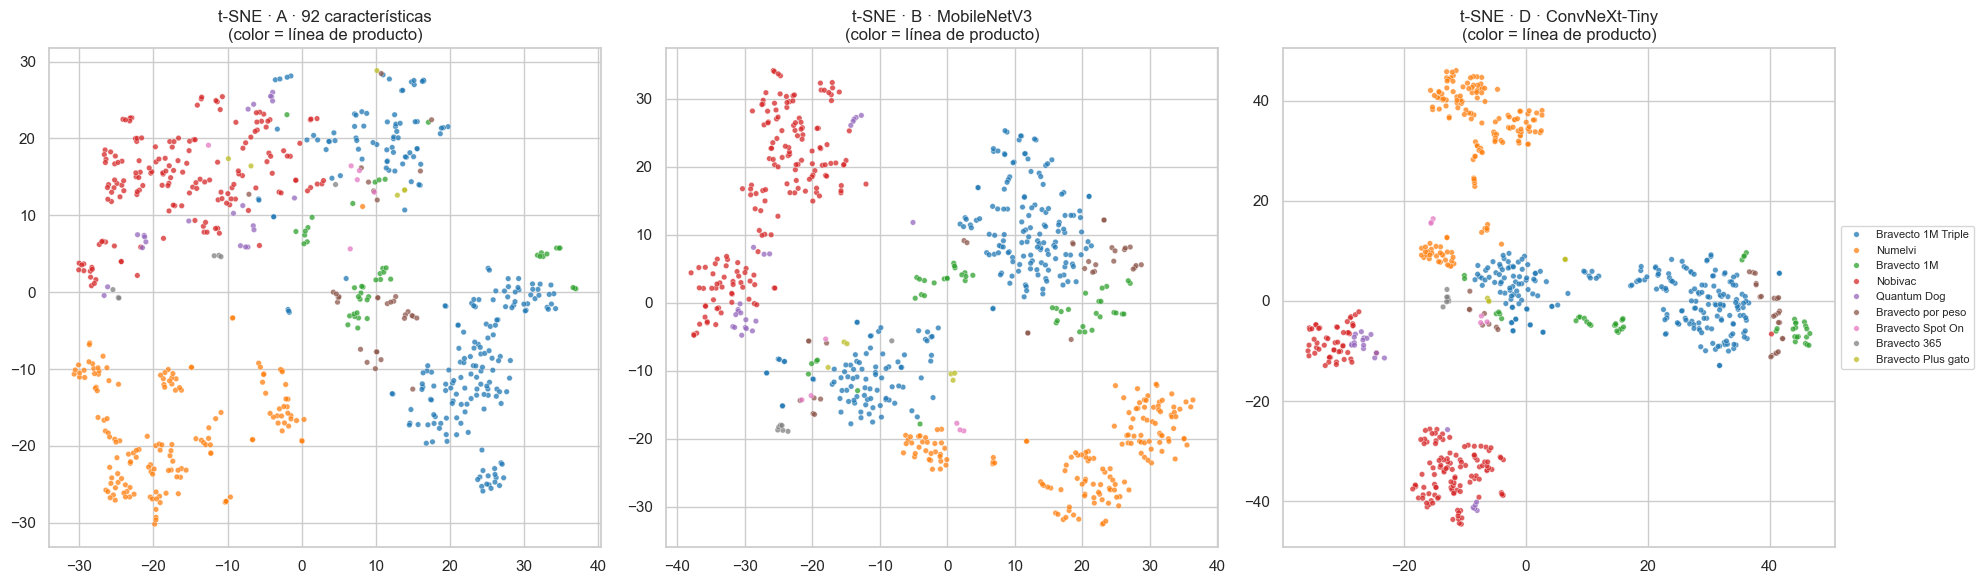

In [10]:
# ¿Cómo se agrupan los productos en cada representación? (t-SNE de todo el conjunto, solo para visualizar)
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for k, (ax, (name, Xv)) in enumerate(zip(axes, [("A · 92 características", X_A), ("B · MobileNetV3", X_B), ("D · ConvNeXt-Tiny", X_D)])):
    Z = TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED).fit_transform(StandardScaler().fit_transform(Xv))
    sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=df.linea.values, s=16, alpha=0.75, ax=ax, palette="tab10", legend=(k == 2))
    ax.set_title(f"t-SNE · {name}\n(color = línea de producto)"); ax.set_xlabel(""); ax.set_ylabel("")
axes[2].legend(fontsize=8, loc="center left", bbox_to_anchor=(1.0, 0.5)); fig.tight_layout(); plt.show()

### 4.1 ¿Qué extractor de CNN conviene?

Para no elegir la red por intuición, se comparan cuatro extractores preentrenados con los dos algoritmos más simples (regresión logística y LDA, hiperparámetros por defecto) y la misma validación cruzada agrupada por foto sobre el entrenamiento. Es un diagnóstico de la representación; la comparación completa de algoritmos es la sección 6.

In [11]:
extract_macro_f1 = make_scorer(lambda a, b: f1_score(a, b, labels=np.unique(a), average="macro", zero_division=0))
ext_rows = []
for name in ["MobileNetV3-Large", "ConvNeXt-Tiny", "ResNet-50", "EfficientNet-B0"]:
    if name in EMB:
        Xe = EMB[name]
    else:
        Xe, EXTRACT_MS[name], N_PARAMS[name] = extract_embeddings(name)
    row = {"extractor": name, "dimensión": Xe.shape[1], "parámetros_M": N_PARAMS[name], "ms_por_producto_CPU": EXTRACT_MS[name]}
    for mname, est in [("Regresión logística", make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000))),
                       ("LDA", make_pipeline(StandardScaler(), LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto")))]:
        row[f"macroF1_CV · {mname}"] = cross_validate(est, Xe[train_idx], ytr, groups=gtr, cv=cv, scoring=extract_macro_f1, n_jobs=-1)["test_score"].mean()
    ext_rows.append(row)
ext_tbl = pd.DataFrame(ext_rows).set_index("extractor"); display(ext_tbl.round(3))

,dimensión,parámetros_M,ms_por_producto_CPU,macroF1_CV · Regresión logística,macroF1_CV · LDA
extractor,,,,,
MobileNetV3-Large,960,2.972,54.918,0.400,0.406
ConvNeXt-Tiny,768,27.820,269.349,0.511,0.494
ResNet-50,2048,23.508,22.572,0.423,0.409
EfficientNet-B0,1280,4.008,112.210,0.399,0.355


## 5. Los modelos

Se construyen **8 algoritmos individuales** de familias distintas. Ninguno es un ensamble (se excluyen bosques aleatorios, *bagging* y *boosting*). En esta primera pasada se usan **hiperparámetros por defecto** de scikit-learn, con dos ajustes mínimos de sentido común: `class_weight="balanced"` donde existe (compensa el desbalance) y, en el discriminante lineal, el solver `lsqr` con *shrinkage* automático (el solver por defecto no es estable cuando hay más variables que observaciones). Esto deja claro cuánto aporta después el ajuste fino.

| Algoritmo | Familia | Qué aporta para este problema | Hiperparámetros que se ajustarán |
|---|---|---|---|
| Regresión logística | lineal, probabilístico | baseline del Avance 3; coeficientes interpretables | C, `class_weight` |
| SVM lineal | lineal, margen máximo | robusto con muchas variables y pocas filas | C, pérdida, `class_weight` |
| SVM RBF | no lineal, *kernel* | fronteras curvas sin construir variables nuevas | C, γ, `class_weight` |
| k vecinos (kNN) | basado en instancias | no asume forma del modelo; útil si cada producto tiene "vecinos" visuales | k, pesos, métrica |
| Árbol de decisión | reglas jerárquicas | totalmente interpretable | profundidad, hojas mínimas, poda |
| Naive Bayes gaussiano | generativo, independencia | muy rápido; referencia de simplicidad | suavizado de varianza |
| Análisis discriminante lineal (LDA) | generativo, lineal | eficaz con pocas muestras por clase (con *shrinkage*) | *shrinkage* |
| Red neuronal (MLP) | no lineal, aprendizaje de capas | puede combinar variables de forma flexible | capas, α, tasa de aprendizaje, activación |

Todos los pipelines estandarizan las variables dentro de cada pliegue y admiten un paso opcional de **PCA** (se ajusta en §8).

In [12]:
MODELS = {
    "Regresión logística":          lambda: make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000)),
    "SVM lineal":                   lambda: make_pipeline(StandardScaler(), LinearSVC(class_weight="balanced", dual="auto", max_iter=3000)),
    "SVM RBF":                      lambda: make_pipeline(StandardScaler(), SVC(class_weight="balanced")),
    "k vecinos (kNN)":              lambda: make_pipeline(StandardScaler(), KNeighborsClassifier()),
    "Árbol de decisión":            lambda: DecisionTreeClassifier(class_weight="balanced", random_state=SEED),
    "Naive Bayes gaussiano":        lambda: make_pipeline(StandardScaler(), GaussianNB()),
    "Análisis discriminante (LDA)": lambda: make_pipeline(StandardScaler(), LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto")),
    "Red neuronal (MLP)":           lambda: make_pipeline(StandardScaler(), MLPClassifier(max_iter=500, random_state=SEED)),
}
print(f"{len(MODELS)} algoritmos × {len(VIEWS)} representaciones = {len(MODELS) * len(VIEWS)} configuraciones")

8 algoritmos × 5 representaciones = 40 configuraciones


## 6. Métricas y comparación

**Métrica principal: macro-F1 sobre las clases presentes en la verdad de terreno** (misma que en el Avance 3). Cada producto pesa igual, así que no se premia acertar solo los frecuentes; es lo que importa para un inventario donde cada presentación cuenta.

**Métricas complementarias** (todas calculadas en validación cruzada agrupada por foto, sobre entrenamiento):

- ***Balanced accuracy*:** recall promedio por clase; otra vista del desbalance.
- **Top-3 accuracy:** ¿la clase real está entre las 3 sugerencias del modelo? Mide cuánto sirve el modelo si un operador confirma entre pocas opciones.
- **Exactitud por línea de producto:** ¿al menos se identificó la familia correcta? Distingue errores cercanos de graves.
- **Tiempo de entrenamiento** (promedio por pliegue, en segundos).

También se reporta el macro-F1 de entrenamiento para vigilar el sobreajuste.

In [13]:
def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, labels=np.unique(y_true), average="macro", zero_division=0)
macro_f1_scorer = make_scorer(macro_f1)

def class_scores(est, X_):
    return est.predict_proba(X_) if hasattr(est, "predict_proba") else est.decision_function(X_)

def top3_scorer(est, X_, y_):
    top = est.classes_[np.argsort(-class_scores(est, X_), axis=1)[:, :3]]
    return float(np.mean([t in row for t, row in zip(y_, top)]))

def linea_scorer(est, X_, y_):
    return float(np.mean([linea(a) == linea(b) for a, b in zip(y_, est.predict(X_))]))

SCORING = {"macro_f1": macro_f1_scorer, "bal_acc": "balanced_accuracy", "top3": top3_scorer, "acc_linea": linea_scorer}

In [14]:
# Etapa 1: 8 algoritmos × 3 representaciones, hiperparámetros por defecto, validación cruzada de 5 pliegues agrupada por foto (solo entrenamiento).
t_stage1 = time.time(); rows = []
for view, Xv in VIEWS.items():
    for mname, make in MODELS.items():
        r = cross_validate(make(), Xv[train_idx], ytr, groups=gtr, cv=cv, scoring=SCORING, return_train_score=True, n_jobs=-1)
        rows.append({"modelo": mname, "características": view,
                     "macroF1_CV": r["test_macro_f1"].mean(), "desv": r["test_macro_f1"].std(), "macroF1_train": r["train_macro_f1"].mean(),
                     "bal_acc": r["test_bal_acc"].mean(), "top3": r["test_top3"].mean(), "acc_línea": r["test_acc_linea"].mean(),
                     "t_entren_s": r["fit_time"].mean()})
    print(f"  {view} listo ({time.time() - t_stage1:.0f} s acumulados)")

# Referencias: azar (estratificado, promedio de semillas) y el baseline del Avance 3 (regresión logística, C = 0.3, 92 características)
ref = []
for name, est in [("Referencia · clase mayoritaria", DummyClassifier(strategy="most_frequent")),
                  ("Referencia · Avance 3 (LR, C=0.3, A)", make_pipeline(StandardScaler(), LogisticRegression(C=0.3, class_weight="balanced", max_iter=2000)))]:
    r = cross_validate(est, X_A[train_idx], ytr, groups=gtr, cv=cv, scoring=SCORING, return_train_score=True, n_jobs=-1)
    ref.append({"modelo": name, "características": "A · 92 características", "macroF1_CV": r["test_macro_f1"].mean(), "desv": r["test_macro_f1"].std(),
                "macroF1_train": r["train_macro_f1"].mean(), "bal_acc": r["test_bal_acc"].mean(), "top3": r["test_top3"].mean(),
                "acc_línea": r["test_acc_linea"].mean(), "t_entren_s": r["fit_time"].mean()})
stage1 = pd.DataFrame(rows).sort_values("macroF1_CV", ascending=False).reset_index(drop=True)
stage1.index += 1
print(f"Etapa 1 terminada en {time.time() - t_stage1:.0f} s")
display(stage1.round(3))
display(pd.DataFrame(ref).round(3))

  A · 92 características listo (2 s acumulados)


  B · MobileNetV3 (960) listo (13 s acumulados)


  C · A + B (1052) listo (27 s acumulados)


  D · ConvNeXt-T (768) listo (42 s acumulados)


  E · A + D (860) listo (60 s acumulados)
Etapa 1 terminada en 60 s


,modelo,características,macroF1_CV,desv,macroF1_train,bal_acc,top3,acc_línea,t_entren_s
1,Regresión logística,E · A + D (860),0.530,0.117,1.000,0.569,0.693,0.923,0.117
2,Análisis discriminante (LDA),E · A + D (860),0.513,0.115,0.997,0.556,0.705,0.897,0.812
3,Regresión logística,D · ConvNeXt-T (768),0.511,0.135,1.000,0.549,0.690,0.921,0.109
4,Análisis discriminante (LDA),D · ConvNeXt-T (768),0.494,0.122,0.995,0.525,0.671,0.881,0.454
5,SVM lineal,E · A + D (860),0.490,0.135,1.000,0.531,0.657,0.820,11.516
6,Red neuronal (MLP),E · A + D (860),0.466,0.133,1.000,0.491,0.631,0.880,0.741
7,Análisis discriminante (LDA),C · A + B (1052),0.456,0.107,1.000,0.502,0.667,0.908,1.437
8,SVM lineal,D · ConvNeXt-T (768),0.441,0.139,1.000,0.476,0.610,0.771,9.975
9,Regresión logística,C · A + B (1052),0.440,0.127,1.000,0.483,0.685,0.906,0.138
10,SVM lineal,C · A + B (1052),0.416,0.131,1.000,0.475,0.579,0.772,6.108


,modelo,características,macroF1_CV,desv,macroF1_train,bal_acc,top3,acc_línea,t_entren_s
0,Referencia · clase mayoritaria,A · 92 características,0.001,0.001,0.005,0.035,0.044,0.103,0.000
1,"Referencia · Avance 3 (LR, C=0.3, A)",A · 92 características,0.382,0.116,0.980,0.419,0.658,0.846,0.047


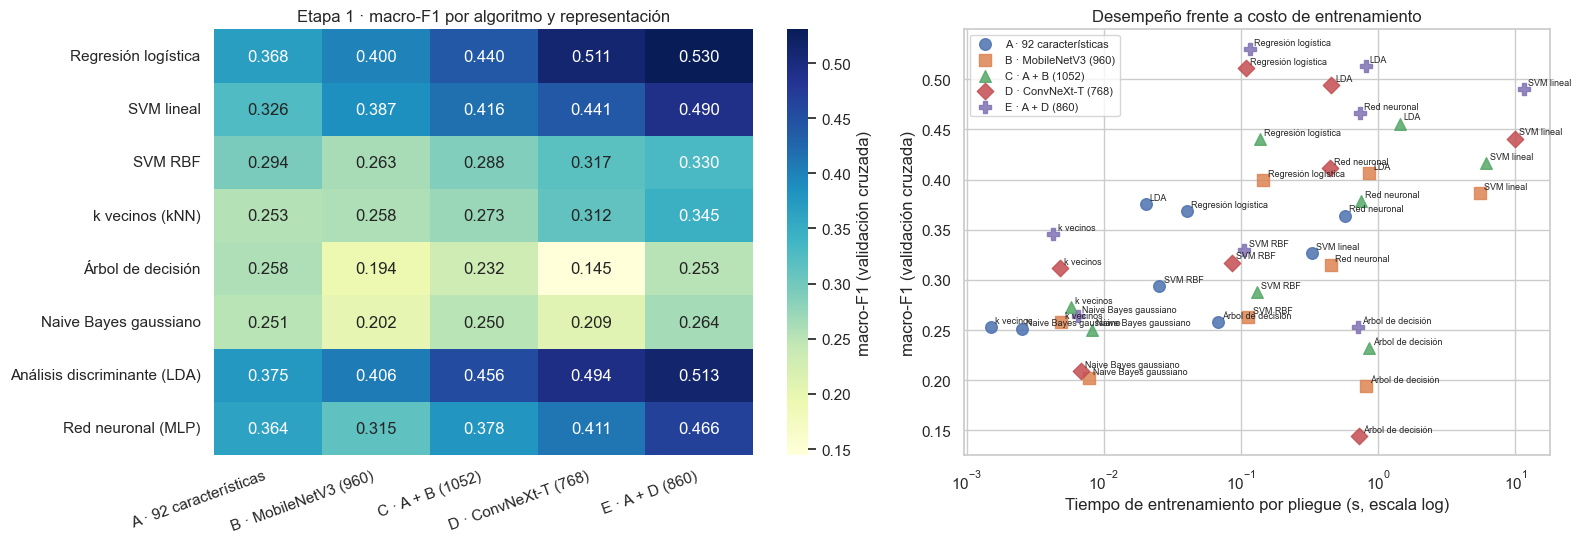

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.6), gridspec_kw={"width_ratios": [1.15, 1]})
pivot = stage1.pivot(index="modelo", columns="características", values="macroF1_CV").loc[list(MODELS)]
sns.heatmap(pivot, annot=True, fmt=".3f", cmap="YlGnBu", ax=axes[0], cbar_kws={"label": "macro-F1 (validación cruzada)"})
axes[0].set_title("Etapa 1 · macro-F1 por algoritmo y representación"); axes[0].set_ylabel(""); axes[0].set_xlabel("")
plt.setp(axes[0].get_xticklabels(), rotation=20, ha="right")
for view, marker in zip(VIEWS, ["o", "s", "^", "D", "P"]):
    s = stage1[stage1["características"] == view]
    axes[1].scatter(s.t_entren_s, s.macroF1_CV, marker=marker, s=70, label=view, alpha=0.85)
    for _, r in s.iterrows():
        axes[1].annotate(r.modelo.split(" (")[0].replace("Análisis discriminante", "LDA"), (r.t_entren_s, r.macroF1_CV), fontsize=6.5, xytext=(3, 3), textcoords="offset points")
axes[1].set_xscale("log"); axes[1].set_xlabel("Tiempo de entrenamiento por pliegue (s, escala log)"); axes[1].set_ylabel("macro-F1 (validación cruzada)")
axes[1].set_title("Desempeño frente a costo de entrenamiento"); axes[1].legend(fontsize=8); fig.tight_layout(); plt.show()

## 7. Selección de los dos mejores

Cada algoritmo se representa por **su mejor representación** en la validación cruzada (así un algoritmo no ocupa los dos lugares con representaciones distintas) y se ordenan por macro-F1. Los dos primeros pasan al ajuste fino.

In [16]:
best_per_model = stage1.loc[stage1.groupby("modelo").macroF1_CV.idxmax()].sort_values("macroF1_CV", ascending=False).reset_index(drop=True)
best_per_model.index += 1
display(best_per_model[["modelo", "características", "macroF1_CV", "desv", "bal_acc", "top3", "acc_línea", "t_entren_s"]].round(3))
TOP2 = best_per_model.head(2)[["modelo", "características"]].values.tolist()
print("Pasan al ajuste fino:", [f"{m} sobre {v}" for m, v in TOP2])

,modelo,características,macroF1_CV,desv,bal_acc,top3,acc_línea,t_entren_s
1,Regresión logística,E · A + D (860),0.530,0.117,0.569,0.693,0.923,0.117
2,Análisis discriminante (LDA),E · A + D (860),0.513,0.115,0.556,0.705,0.897,0.812
3,SVM lineal,E · A + D (860),0.490,0.135,0.531,0.657,0.820,11.516
4,Red neuronal (MLP),E · A + D (860),0.466,0.133,0.491,0.631,0.880,0.741
5,k vecinos (kNN),E · A + D (860),0.345,0.101,0.389,0.607,0.890,0.004
6,SVM RBF,E · A + D (860),0.330,0.132,0.376,0.571,0.876,0.106
7,Naive Bayes gaussiano,E · A + D (860),0.264,0.089,0.317,0.507,0.792,0.006
8,Árbol de decisión,A · 92 características,0.258,0.050,0.277,0.350,0.663,0.068


Pasan al ajuste fino: ['Regresión logística sobre E · A + D (860)', 'Análisis discriminante (LDA) sobre E · A + D (860)']


## 8. Ajuste fino de los dos mejores

Se usa **búsqueda aleatoria** en dos rondas (Bergstra y Bengio, 2012; Géron, 2022, cap. 2, *Fine-Tune Your Model*): para espacios con varios hiperparámetros continuos es más eficiente que una rejilla porque explora más valores distintos de cada uno con el mismo presupuesto.

1. **Ronda 1, exploración amplia:** 80 configuraciones sorteadas en todo el espacio.
2. **Ronda 2, refinamiento:** 60 configuraciones más, con los rangos continuos estrechados alrededor del mejor valor de la ronda 1 (un factor de 5 en escala logarítmica; ±4 en enteros).

Cada configuración se evalúa con validación cruzada de 5 pliegues **agrupada por foto** y se optimiza el macro-F1. Además de los hiperparámetros del algoritmo, el espacio incluye un paso opcional de **PCA** (número de componentes) antes del clasificador, que actúa como un hiperparámetro de "arquitectura" de la representación. Los datos de prueba no intervienen. Como la configuración final se elige con las mismas validaciones cruzadas que se usan para compararla con el valor por defecto, la mejora medida en validación es ligeramente optimista; por eso la confirmación se hace después en la prueba, que no se tocó.

### 8.1 Arquitectura de la representación: tamaño de entrada de la CNN

Antes de ajustar los clasificadores se revisa un hiperparámetro de la **representación**: el lado mayor al que se redimensiona cada recorte antes de entrar a ConvNeXt-Tiny (224, 320 o 448 px). Un tamaño mayor conserva más detalle del texto del empaque pero cuesta más tiempo de cómputo y se aleja de la escala con la que se preentrenó la red. Se evalúa con los dos algoritmos seleccionados, hiperparámetros por defecto y la misma validación cruzada agrupada por foto (solo entrenamiento).

,lado_mayor_px,modelo,macroF1_CV,desv,ms_extracción_por_producto
0,224,Regresión logística,0.466,0.139,203.287
1,224,Análisis discriminante (LDA),0.497,0.125,203.287
2,320,Regresión logística,0.511,0.135,269.349
3,320,Análisis discriminante (LDA),0.494,0.122,269.349
4,448,Regresión logística,0.433,0.144,403.929
5,448,Análisis discriminante (LDA),0.468,0.123,403.929


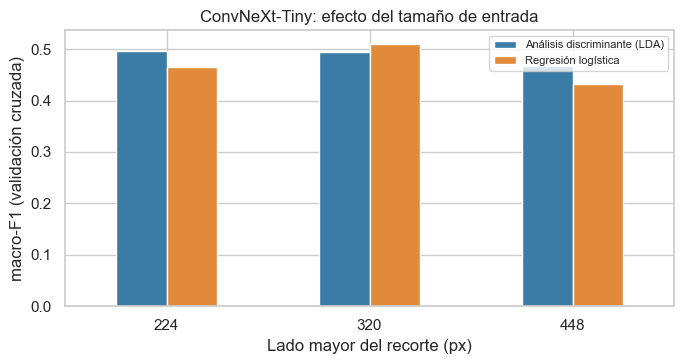

Mejor tamaño por algoritmo: {'Análisis discriminante (LDA)': 224, 'Regresión logística': 320} | se conserva 320 px (el usado en las representaciones D y E)


In [17]:
def embed_at(long_side):
    emb_, ms_, _ = extract_embeddings("ConvNeXt-Tiny", long_side=long_side)
    return emb_, ms_

size_rows = []
for size in (224, 320, 448):
    Xs_, ms_ = (X_D, EXTRACT_MS["ConvNeXt-Tiny"]) if size == 320 else embed_at(size)
    for mname, _ in TOP2:
        r = cross_validate(MODELS[mname](), Xs_[train_idx], ytr, groups=gtr, cv=cv, scoring=SCORING, n_jobs=-1)
        size_rows.append({"lado_mayor_px": size, "modelo": mname, "macroF1_CV": r["test_macro_f1"].mean(), "desv": r["test_macro_f1"].std(), "ms_extracción_por_producto": ms_})
size_tbl = pd.DataFrame(size_rows); display(size_tbl.round(3))
piv = size_tbl.pivot(index="lado_mayor_px", columns="modelo", values="macroF1_CV")
fig, ax = plt.subplots(figsize=(7, 3.8)); piv.plot.bar(ax=ax, rot=0, color=["#3a7ca5", "#e08a3a"]); ax.set_ylabel("macro-F1 (validación cruzada)"); ax.set_xlabel("Lado mayor del recorte (px)")
ax.set_title("ConvNeXt-Tiny: efecto del tamaño de entrada"); ax.legend(fontsize=8); fig.tight_layout(); plt.show()
print("Mejor tamaño por algoritmo:", {m: int(piv[m].idxmax()) for m in piv.columns}, "| se conserva 320 px (el usado en las representaciones D y E)")

### 8.2 Búsqueda aleatoria de hiperparámetros del clasificador

In [18]:
def dims(view): return VIEWS[view].shape[1]
def pca_options(view): return [None] + [n for n in (16, 32, 64, 128, 256) if n < 0.8 * dims(view)]

# ("log", lo, hi) = log-uniforme; ("int", lo, hi) = entero uniforme; lista = categórico
SPACES = {
    "Regresión logística": (lambda: LogisticRegression(max_iter=2000), {"C": ("log", 1e-4, 1e2), "class_weight": [None, "balanced"]}),
    "SVM lineal": (lambda: LinearSVC(dual="auto", max_iter=3000), {"C": ("log", 1e-5, 1e0), "loss": ["hinge", "squared_hinge"], "class_weight": [None, "balanced"]}),
    "SVM RBF": (lambda: SVC(), {"C": ("log", 1e-1, 1e3), "gamma": ("log", 1e-5, 1e-1), "class_weight": [None, "balanced"]}),
    "k vecinos (kNN)": (lambda: KNeighborsClassifier(), {"n_neighbors": ("int", 1, 25), "weights": ["uniform", "distance"], "metric": ["euclidean", "manhattan", "cosine"]}),
    "Árbol de decisión": (lambda: DecisionTreeClassifier(random_state=SEED), {"max_depth": [3, 5, 8, 12, 20, None], "min_samples_leaf": ("int", 1, 10), "criterion": ["gini", "entropy"],
                                                                              "ccp_alpha": ("log", 1e-4, 1e-1), "class_weight": [None, "balanced"]}),
    "Naive Bayes gaussiano": (lambda: GaussianNB(), {"var_smoothing": ("log", 1e-10, 1e0)}),
    "Análisis discriminante (LDA)": (lambda: LinearDiscriminantAnalysis(solver="lsqr"), {"shrinkage": ["auto"] + [round(v, 2) for v in np.linspace(0.02, 0.98, 25)]}),
    "Red neuronal (MLP)": (lambda: MLPClassifier(max_iter=500, random_state=SEED), {"hidden_layer_sizes": [(64,), (128,), (256,), (128, 64), (256, 128)], "alpha": ("log", 1e-5, 1e0),
                                                                                    "learning_rate_init": ("log", 1e-4, 3e-2), "activation": ["relu", "tanh"]}),
}
def to_dist(v):
    if isinstance(v, tuple) and v[0] == "log": return loguniform(v[1], v[2])
    if isinstance(v, tuple) and v[0] == "int": return randint(v[1], v[2] + 1)
    return v
def refine(spec, best_params, width=5):
    new = {}
    for k, v in spec.items():
        b = best_params.get(f"clf__{k}")
        if isinstance(v, tuple) and v[0] == "log" and b: new[k] = ("log", max(v[1], b / width), min(v[2], b * width))
        elif isinstance(v, tuple) and v[0] == "int" and b is not None: new[k] = ("int", max(v[1], b - 4), min(v[2], b + 4))
        else: new[k] = v
    return new
def run_search(mname, view, spec, n_iter, seed):
    pipe = Pipeline([("scale", StandardScaler()), ("pca", PCA(random_state=SEED)), ("clf", SPACES[mname][0]())])
    dist = {"pca__n_components": pca_options(view), **{f"clf__{k}": to_dist(v) for k, v in spec.items()}}
    search = RandomizedSearchCV(pipe, dist, n_iter=n_iter, scoring=macro_f1_scorer, cv=cv, n_jobs=-1, random_state=seed, refit=True, return_train_score=True, error_score="raise")
    return search.fit(VIEWS[view][train_idx], ytr, groups=gtr)

N1, N2 = 80, 60
searches, rounds, tune_rows = {}, {}, []
for mname, view in TOP2:
    t0 = time.time()
    s1 = run_search(mname, view, SPACES[mname][1], N1, SEED)
    s2 = run_search(mname, view, refine(SPACES[mname][1], s1.best_params_), N2, SEED + 1)
    best = s2 if s2.best_score_ > s1.best_score_ else s1
    searches[mname] = (best, view); rounds[mname] = (s1, s2)
    base = stage1[(stage1.modelo == mname) & (stage1["características"] == view)].iloc[0]
    tune_rows.append({"modelo": mname, "características": view, "configuraciones": N1 + N2, "ajustes_totales": (N1 + N2) * cv.n_splits,
                      "macroF1_CV_defecto": base.macroF1_CV, "macroF1_CV_ronda1": s1.best_score_, "macroF1_CV_ronda2": s2.best_score_,
                      "macroF1_CV_ajustado": best.best_score_, "mejora": best.best_score_ - base.macroF1_CV, "t_búsqueda_s": time.time() - t0})
    print(f"{mname}: {time.time() - t0:.0f} s | defecto {base.macroF1_CV:.3f} → ronda 1 {s1.best_score_:.3f} → ronda 2 {s2.best_score_:.3f}")
tune = pd.DataFrame(tune_rows).set_index("modelo"); display(tune.round(3))
for mname, (s_, v_) in searches.items():
    print(f"\nMejores hiperparámetros · {mname} ({v_}):"); display(pd.Series(s_.best_params_, name="valor").to_frame().T.astype(str))

Regresión logística: 47 s | defecto 0.530 → ronda 1 0.539 → ronda 2 0.544


Análisis discriminante (LDA): 13 s | defecto 0.513 → ronda 1 0.518 → ronda 2 0.515


,características,configuraciones,ajustes_totales,macroF1_CV_defecto,macroF1_CV_ronda1,macroF1_CV_ronda2,macroF1_CV_ajustado,mejora,t_búsqueda_s
modelo,,,,,,,,,
Regresión logística,E · A + D (860),140,700,0.530,0.539,0.544,0.544,0.013,47.094
Análisis discriminante (LDA),E · A + D (860),140,700,0.513,0.518,0.515,0.518,0.004,12.756



Mejores hiperparámetros · Regresión logística (E · A + D (860)):


,clf__C,clf__class_weight,pca__n_components
valor,15.88284554096028,balanced,256



Mejores hiperparámetros · Análisis discriminante (LDA) (E · A + D (860)):


,pca__n_components,clf__shrinkage
valor,nan,0.22


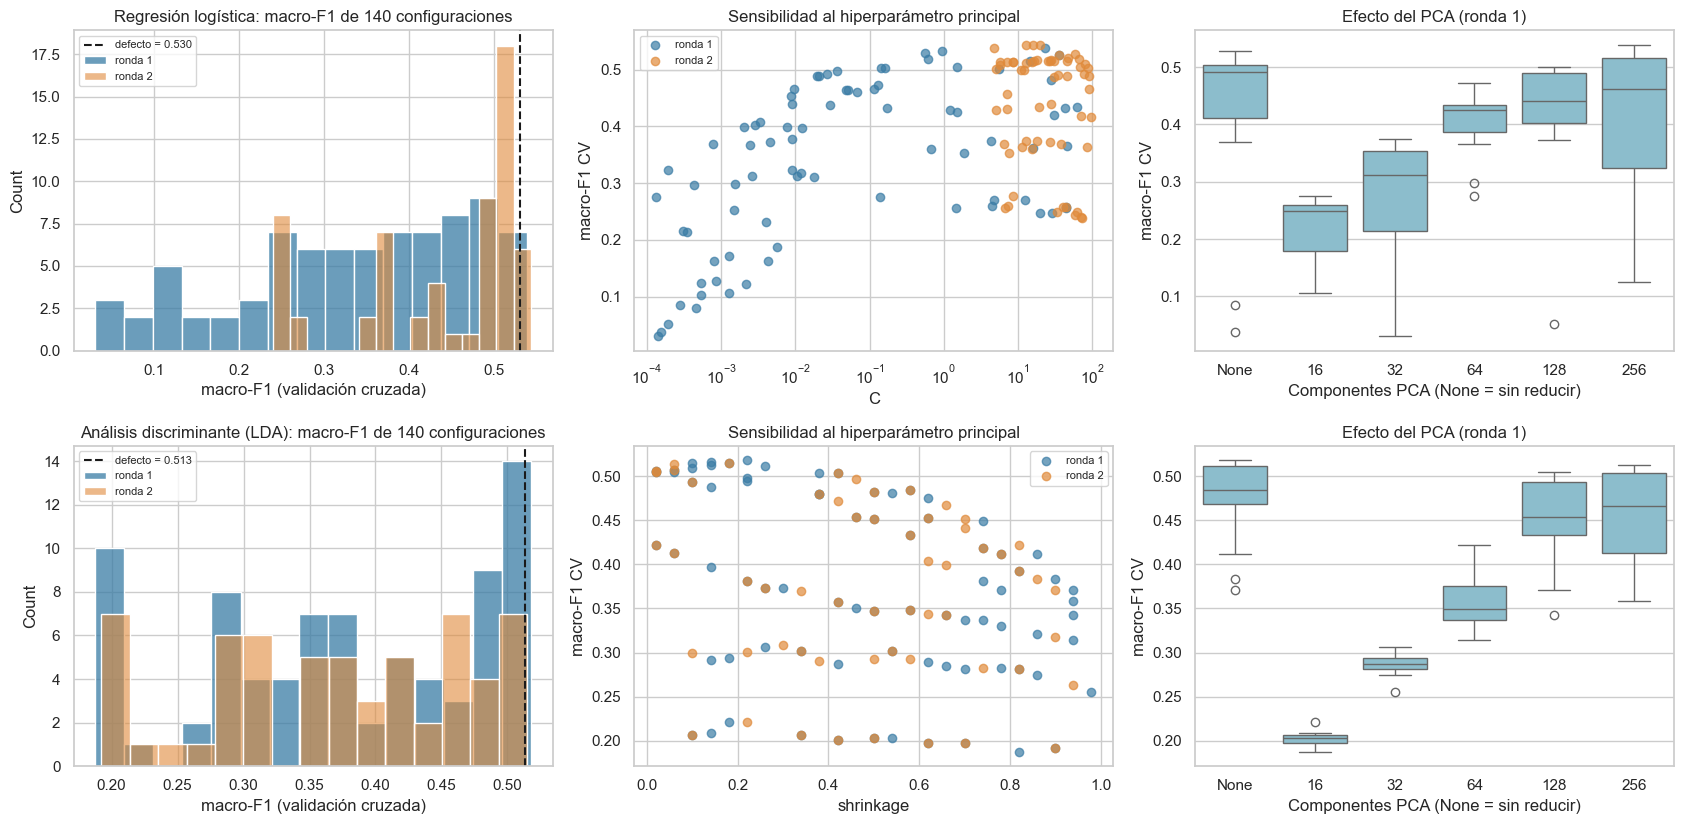


5 mejores configuraciones · Regresión logística


,ronda,mean_test_score,std_test_score,mean_train_score,param_clf__C,param_clf__class_weight,param_pca__n_components
26,2,0.5435,0.1276,1.0,15.8828,balanced,256
14,2,0.5432,0.1267,1.0,12.9418,balanced,None
6,2,0.5429,0.1289,1.0,19.6151,balanced,256
23,1,0.5388,0.1310,1.0,23.3864,balanced,256
58,2,0.5373,0.1201,1.0,4.7832,balanced,None



5 mejores configuraciones · Análisis discriminante (LDA)


,ronda,mean_test_score,std_test_score,mean_train_score,param_pca__n_components,param_clf__shrinkage
43,1,0.5177,0.1141,0.9992,None,0.22
14,1,0.5155,0.1177,1.0000,None,0.14
21,1,0.5150,0.1200,1.0000,None,0.1
27,2,0.5150,0.1154,1.0000,None,0.18
15,1,0.5150,0.1154,1.0000,None,0.18


In [19]:
# ¿Qué tan profundo fue el espacio explorado y qué hiperparámetros importaron?
fig, axes = plt.subplots(len(searches), 3, figsize=(17, 4.2 * len(searches)))
axes = np.atleast_2d(axes)
for row, (mname, (s_, view)) in enumerate(searches.items()):
    r1, r2 = (pd.DataFrame(x.cv_results_) for x in rounds[mname]); base = stage1[(stage1.modelo == mname) & (stage1["características"] == view)].iloc[0].macroF1_CV
    sns.histplot(r1.mean_test_score, bins=15, ax=axes[row, 0], color="#3a7ca5", label="ronda 1"); sns.histplot(r2.mean_test_score, bins=15, ax=axes[row, 0], color="#e08a3a", label="ronda 2", alpha=0.6)
    axes[row, 0].axvline(base, color="k", ls="--", label=f"defecto = {base:.3f}"); axes[row, 0].legend(fontsize=8)
    axes[row, 0].set_title(f"{mname}: macro-F1 de {len(r1) + len(r2)} configuraciones"); axes[row, 0].set_xlabel("macro-F1 (validación cruzada)")
    numeric = [c for c in r1.columns if c.startswith("param_clf__") and pd.to_numeric(r1[c], errors="coerce").nunique() > 6]
    if numeric:
        col = numeric[0]
        for res_, color, lab in [(r1, "#3a7ca5", "ronda 1"), (r2, "#e08a3a", "ronda 2")]:
            v = pd.to_numeric(res_[col], errors="coerce"); ok = v.notna(); axes[row, 1].scatter(v[ok], res_.mean_test_score[ok], c=color, alpha=0.7, label=lab)
        v_all = pd.to_numeric(r1[col], errors="coerce").dropna(); axes[row, 1].set_xscale("log" if v_all.max() / max(v_all.min(), 1e-12) > 50 else "linear")
        axes[row, 1].set_xlabel(col.replace("param_clf__", "")); axes[row, 1].set_ylabel("macro-F1 CV"); axes[row, 1].set_title("Sensibilidad al hiperparámetro principal"); axes[row, 1].legend(fontsize=8)
    sns.boxplot(data=r1.assign(pca=r1["param_pca__n_components"].astype(str)), x="pca", y="mean_test_score", ax=axes[row, 2], color="#81c3d7", order=[str(o) for o in pca_options(view)])
    axes[row, 2].set_xlabel("Componentes PCA (None = sin reducir)"); axes[row, 2].set_ylabel("macro-F1 CV"); axes[row, 2].set_title("Efecto del PCA (ronda 1)")
fig.tight_layout(); plt.show()
for mname, (s_, view) in searches.items():
    allres = pd.concat([pd.DataFrame(x.cv_results_).assign(ronda=i + 1) for i, x in enumerate(rounds[mname])]).sort_values("mean_test_score", ascending=False).head(5)
    print(f"\n5 mejores configuraciones · {mname}"); display(allres[["ronda", "mean_test_score", "std_test_score", "mean_train_score"] + [c for c in allres.columns if c.startswith("param_")]].round(4))

## 9. Evaluación de los modelos ajustados en prueba

Los dos modelos ajustados, junto con el baseline del Avance 3, se evalúan **una sola vez** sobre las 10 fotos de prueba. Como son pocas fotos, se incluye un **intervalo de incertidumbre por *bootstrap* de fotografías** (se remuestrean las fotos de prueba con reemplazo y se recalcula el macro-F1): refleja cuánto cambiaría el resultado con otro conjunto de fotos.

In [20]:
def evaluate_model(est, Xv):
    t0 = time.time(); pred = est.predict(Xv[test_idx]); t_pred = (time.time() - t0)
    for _ in range(4):
        t1 = time.time(); est.predict(Xv[test_idx]); t_pred = min(t_pred, time.time() - t1)
    top3 = top3_scorer(est, Xv[test_idx], yte)
    return pred, {"macroF1_test": macro_f1(yte, pred), "bal_acc_test": balanced_accuracy_score(yte, pred), "top3_test": top3,
                  "acc_línea_test": np.mean([linea(a) == linea(b) for a, b in zip(yte, pred)]), "acc_marca_test": np.mean([marca(a) == marca(b) for a, b in zip(yte, pred)]),
                  "ms_por_1000_prod": t_pred / len(yte) * 1e6}

def bootstrap_macro_f1(pred, n=500):
    rng = np.random.default_rng(SEED); photos = np.unique(gte); out = []
    idx_by = {p: np.where(gte == p)[0] for p in photos}
    for _ in range(n):
        pick = np.concatenate([idx_by[p] for p in rng.choice(photos, len(photos), replace=True)])
        out.append(macro_f1(yte[pick], pred[pick]))
    return np.percentile(out, [2.5, 97.5])

def count_error(pred):
    d = pd.DataFrame({"foto": gte, "real": yte, "pred": pred}); rows_ = []
    for foto, g in d.groupby("foto"):
        a, b = Counter(g.real), Counter(g.pred)
        rows_ += [abs(a[c] - b[c]) for c in set(a) | set(b)]
    return float(np.mean(rows_)), float(np.mean(np.array(rows_) == 0))

# Baseline del Avance 3 (mismos datos y partición) y los dos modelos ajustados
baseline = make_pipeline(StandardScaler(), LogisticRegression(C=0.3, class_weight="balanced", max_iter=2000)).fit(X_A[train_idx], ytr)
entries = [("Baseline Avance 3 (LR, C=0.3)", baseline, X_A, None)] + [(f"{m} (ajustado)", s.best_estimator_, VIEWS[v], (m, v)) for m, (s, v) in searches.items()]
eval_rows, PREDS = [], {}
for name, est, Xv, key in entries:
    pred, met = evaluate_model(est, Xv); lo, hi = bootstrap_macro_f1(pred); mae, exact = count_error(pred); PREDS[name] = pred
    eval_rows.append({"modelo": name, "características": key[1] if key else "A · 92 características", **met, "IC95_macroF1_test": f"[{lo:.3f}, {hi:.3f}]",
                      "error_conteo": mae, "conteos_exactos": exact})
final_tbl = pd.DataFrame(eval_rows).set_index("modelo"); display(final_tbl.round(3))

,características,macroF1_test,bal_acc_test,top3_test,acc_línea_test,acc_marca_test,ms_por_1000_prod,IC95_macroF1_test,error_conteo,conteos_exactos
modelo,,,,,,,,,,
"Baseline Avance 3 (LR, C=0.3)",A · 92 características,0.169,0.173,0.404,0.565,0.913,3.535,"[0.106, 0.331]",3.040,0.093
Regresión logística (ajustado),E · A + D (860),0.253,0.318,0.472,0.602,0.944,7.666,"[0.210, 0.456]",2.861,0.167
Análisis discriminante (LDA) (ajustado),E · A + D (860),0.270,0.349,0.491,0.615,0.963,12.130,"[0.171, 0.512]",3.104,0.224


,macroF1_CV,desv_CV,macroF1_test,IC95_macroF1_test,bal_acc_test,top3_test,acc_línea_test,acc_marca_test,error_conteo,conteos_exactos,ms_por_1000_prod,t_entren_s,tamaño_KB
modelo,,,,,,,,,,,,,
"Baseline Avance 3 (LR, C=0.3)",0.382,0.116,0.169,"[0.106, 0.331]",0.173,0.404,0.565,0.913,3.040,0.093,3.535,0.047,34.298
Regresión logística (ajustado),0.544,0.128,0.253,"[0.210, 0.456]",0.318,0.472,0.602,0.944,2.861,0.167,7.666,12.802,1838.102
Análisis discriminante (LDA) (ajustado),0.518,0.114,0.270,"[0.171, 0.512]",0.349,0.491,0.615,0.963,3.104,0.224,12.130,0.783,5909.807


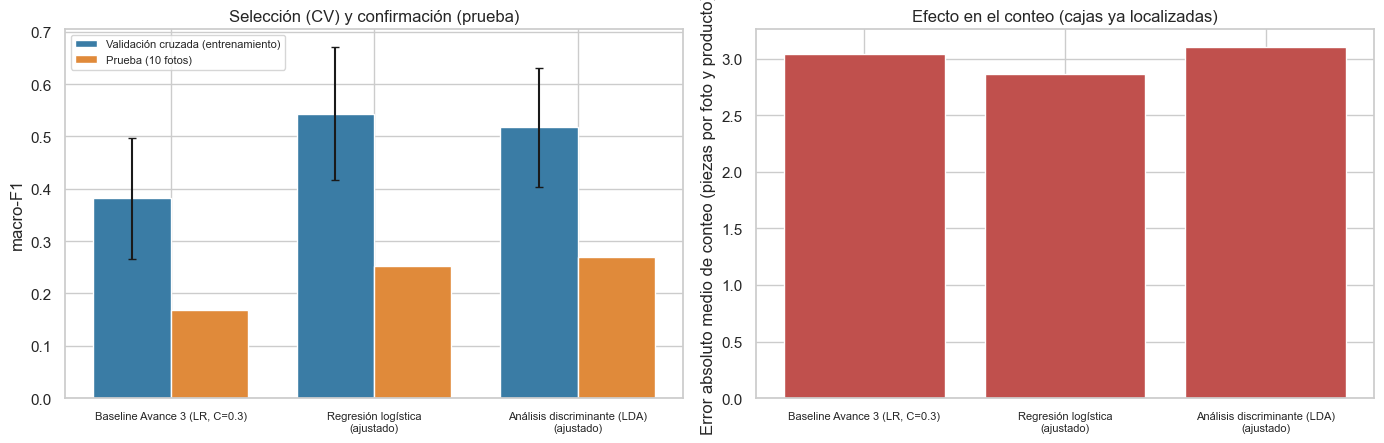

In [21]:
# Comparativa completa: validación cruzada (selección) y prueba (confirmación) para cada modelo final candidato.
BASE = pd.DataFrame(ref).set_index("modelo").loc["Referencia · Avance 3 (LR, C=0.3, A)"]
cmp_rows = []
for name, est, Xv, key in entries:
    if key:
        srch = searches[key[0]][0]
        cv_mean, cv_std, fit_t = srch.best_score_, pd.DataFrame(srch.cv_results_).iloc[srch.best_index_].std_test_score, srch.refit_time_
    else:
        cv_mean, cv_std, fit_t = BASE.macroF1_CV, BASE.desv, BASE.t_entren_s
    cmp_rows.append({"modelo": name, "macroF1_CV": cv_mean, "desv_CV": cv_std, **final_tbl.loc[name, ["macroF1_test", "IC95_macroF1_test", "bal_acc_test", "top3_test", "acc_línea_test", "acc_marca_test", "error_conteo", "conteos_exactos", "ms_por_1000_prod"]].to_dict(),
                     "t_entren_s": fit_t, "tamaño_KB": len(pickle.dumps(est)) / 1024})
cmp = pd.DataFrame(cmp_rows).set_index("modelo")
display(cmp.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
x = np.arange(len(cmp)); w = 0.38
axes[0].bar(x - w / 2, cmp.macroF1_CV, w, yerr=cmp.desv_CV, label="Validación cruzada (entrenamiento)", color="#3a7ca5", capsize=3)
axes[0].bar(x + w / 2, cmp.macroF1_test, w, label="Prueba (10 fotos)", color="#e08a3a")
axes[0].set_xticks(x); axes[0].set_xticklabels([n.replace(" (ajustado)", "\n(ajustado)") for n in cmp.index], fontsize=8); axes[0].set_ylabel("macro-F1"); axes[0].legend(fontsize=8); axes[0].set_title("Selección (CV) y confirmación (prueba)")
axes[1].bar(x, cmp.error_conteo, color="#c0504d"); axes[1].set_xticks(x); axes[1].set_xticklabels([n.replace(" (ajustado)", "\n(ajustado)") for n in cmp.index], fontsize=8)
axes[1].set_ylabel("Error absoluto medio de conteo (piezas por foto y producto)"); axes[1].set_title("Efecto en el conteo (cajas ya localizadas)")
fig.tight_layout(); plt.show()

## 10. Elección del modelo individual final

La elección no depende solo de la métrica principal. Se consideran, además: la **incertidumbre** (desviación entre pliegues e intervalo de la prueba), el **tiempo de entrenamiento e inferencia**, la **complejidad e interpretabilidad**, el **tamaño** del modelo y su **dependencia de una CNN** en producción. La regla que se aplica es la habitual en validación cruzada (*regla de una desviación estándar*): entre los candidatos cuyo macro-F1 de validación está a una desviación del mejor, se prefiere el **más simple e interpretable**.

In [22]:
INTERPRETABILIDAD = {"Regresión logística": "alta (coeficientes por clase)", "SVM lineal": "media-alta (pesos lineales)", "SVM RBF": "baja (vectores de soporte)",
                     "k vecinos (kNN)": "media (casos vecinos)", "Árbol de decisión": "muy alta (reglas)", "Naive Bayes gaussiano": "alta (medias por clase)",
                     "Análisis discriminante (LDA)": "alta (direcciones discriminantes)", "Red neuronal (MLP)": "baja"}
COMPLEJIDAD = {"Árbol de decisión": 1, "Naive Bayes gaussiano": 1, "Regresión logística": 1, "Análisis discriminante (LDA)": 1, "SVM lineal": 2, "k vecinos (kNN)": 2, "SVM RBF": 3, "Red neuronal (MLP)": 4}
cand = []
for mname, (s, view) in searches.items():
    r = pd.DataFrame(s.cv_results_).iloc[s.best_index_]
    cand.append({"modelo": mname, "características": view, "macroF1_CV": s.best_score_, "desv_CV": r.std_test_score, "complejidad": COMPLEJIDAD[mname],
                 "interpretabilidad": INTERPRETABILIDAD[mname], "extractor_CNN": ("ConvNeXt-Tiny" if view[0] in "DE" else "MobileNetV3" if view[0] in "BC" else "ninguno"),
                 "extracción_ms_producto": EXTRACT_MS_VIEW[view], "entrada_tras_PCA": s.best_params_["pca__n_components"] or dims(view)})
cand = pd.DataFrame(cand).set_index("modelo")
top_cv = cand.macroF1_CV.max(); top_sd = cand.loc[cand.macroF1_CV.idxmax(), "desv_CV"]
close = cand[cand.macroF1_CV >= top_cv - top_sd]
FINAL_NAME = close.sort_values(["complejidad", "macroF1_CV"], ascending=[True, False]).index[0]
FINAL_SEARCH, FINAL_VIEW = searches[FINAL_NAME]
FINAL = FINAL_SEARCH.best_estimator_
final_row = cmp.loc[f"{FINAL_NAME} (ajustado)"]
display(cand.join(cmp[["macroF1_test", "IC95_macroF1_test", "error_conteo", "t_entren_s", "ms_por_1000_prod", "tamaño_KB"]].rename(index=lambda n: n.replace(" (ajustado)", ""), errors="ignore"), how="left").round(3))
print(f"Candidatos dentro de una desviación del mejor ({top_cv:.3f} ± {top_sd:.3f}): {list(close.index)}")
print(f"MODELO FINAL: {FINAL_NAME} sobre {FINAL_VIEW}")
print("Hiperparámetros:", {k: (float(v) if isinstance(v, np.floating) else v) for k, v in FINAL_SEARCH.best_params_.items()})

,características,macroF1_CV,desv_CV,complejidad,interpretabilidad,extractor_CNN,extracción_ms_producto,entrada_tras_PCA,macroF1_test,IC95_macroF1_test,error_conteo,t_entren_s,ms_por_1000_prod,tamaño_KB
modelo,,,,,,,,,,,,,,
Regresión logística,E · A + D (860),0.544,0.128,1,alta (coeficientes por clase),ConvNeXt-Tiny,275.522,256,0.253,"[0.210, 0.456]",2.861,12.802,7.666,1838.102
Análisis discriminante (LDA),E · A + D (860),0.518,0.114,1,alta (direcciones discriminantes),ConvNeXt-Tiny,275.522,860,0.270,"[0.171, 0.512]",3.104,0.783,12.130,5909.807


Candidatos dentro de una desviación del mejor (0.544 ± 0.128): ['Regresión logística', 'Análisis discriminante (LDA)']
MODELO FINAL: Regresión logística sobre E · A + D (860)
Hiperparámetros: {'clf__C': 15.88284554096028, 'clf__class_weight': 'balanced', 'pca__n_components': 256}


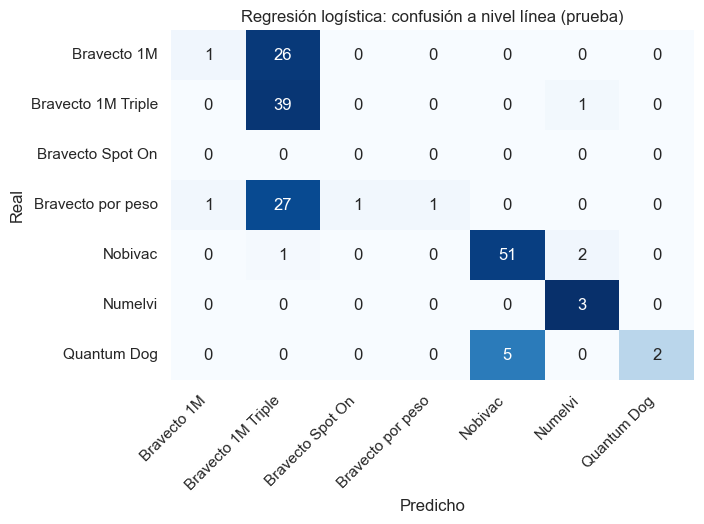

Errores: 108 de 161 | dentro de la misma línea: 40.7%


,,veces
real,predicho,
Nobivac Puppy Dp Plus + Diluente,Nobivac RL,10
Bravecto 500mg 10-20,Bravecto 1M Triple 200 mg 1 x 1 Tab,8
Bravecto 1000mg 20-40,Bravecto 1M Triple 400 mg 3 Tab,5
Quantum Dog DA2PPV+CV 25 DS,Nobivac RL,5
Bravecto 1M Triple 100 mg 1 x1 Tab,Bravecto 1M Triple 600 mg 1x1TAB,5
Nobivac Intra-Trac Oral Bb 25x1ds,Nobivac RL,4
Bravecto 1M 200 mg 1 x1 Tab 117,Bravecto 1M Triple 25 mg 3 tab,4
Bravecto 1M 45 mg 1x1tab 117,Bravecto 1M Triple 400 mg 3 Tab,4


Conteo por (foto, producto): error medio 2.86 piezas | exactos 16.7% (Avance 3: 3.04 piezas | 9.3%)


In [23]:
# Diagnóstico del modelo final: errores por línea de producto, errores frecuentes y conteo.
pred_final = PREDS[f"{FINAL_NAME} (ajustado)"]
lines = sorted(set(map(linea, yte)) | set(map(linea, pred_final)))
cm = confusion_matrix([linea(c) for c in yte], [linea(c) for c in pred_final], labels=lines)
fig, ax = plt.subplots(figsize=(7.2, 5.4))
sns.heatmap(cm / cm.sum(1, keepdims=True).clip(1), annot=cm, fmt="d", cmap="Blues", xticklabels=lines, yticklabels=lines, ax=ax, cbar=False)
ax.set_title(f"{FINAL_NAME}: confusión a nivel línea (prueba)"); ax.set_xlabel("Predicho"); ax.set_ylabel("Real"); plt.setp(ax.get_xticklabels(), rotation=45, ha="right"); fig.tight_layout(); plt.show()

err = pd.DataFrame({"real": yte, "predicho": pred_final}); err = err[err.real != err.predicho]
print(f"Errores: {len(err)} de {len(yte)} | dentro de la misma línea: {np.mean([linea(a) == linea(b) for a, b in zip(err.real, err.predicho)]):.1%}")
display(err.groupby(["real", "predicho"]).size().sort_values(ascending=False).head(8).rename("veces").to_frame())
print(f"Conteo por (foto, producto): error medio {final_row.error_conteo:.2f} piezas | exactos {final_row.conteos_exactos:.1%} "
      f"(Avance 3: {cmp.iloc[0].error_conteo:.2f} piezas | {cmp.iloc[0].conteos_exactos:.1%})")

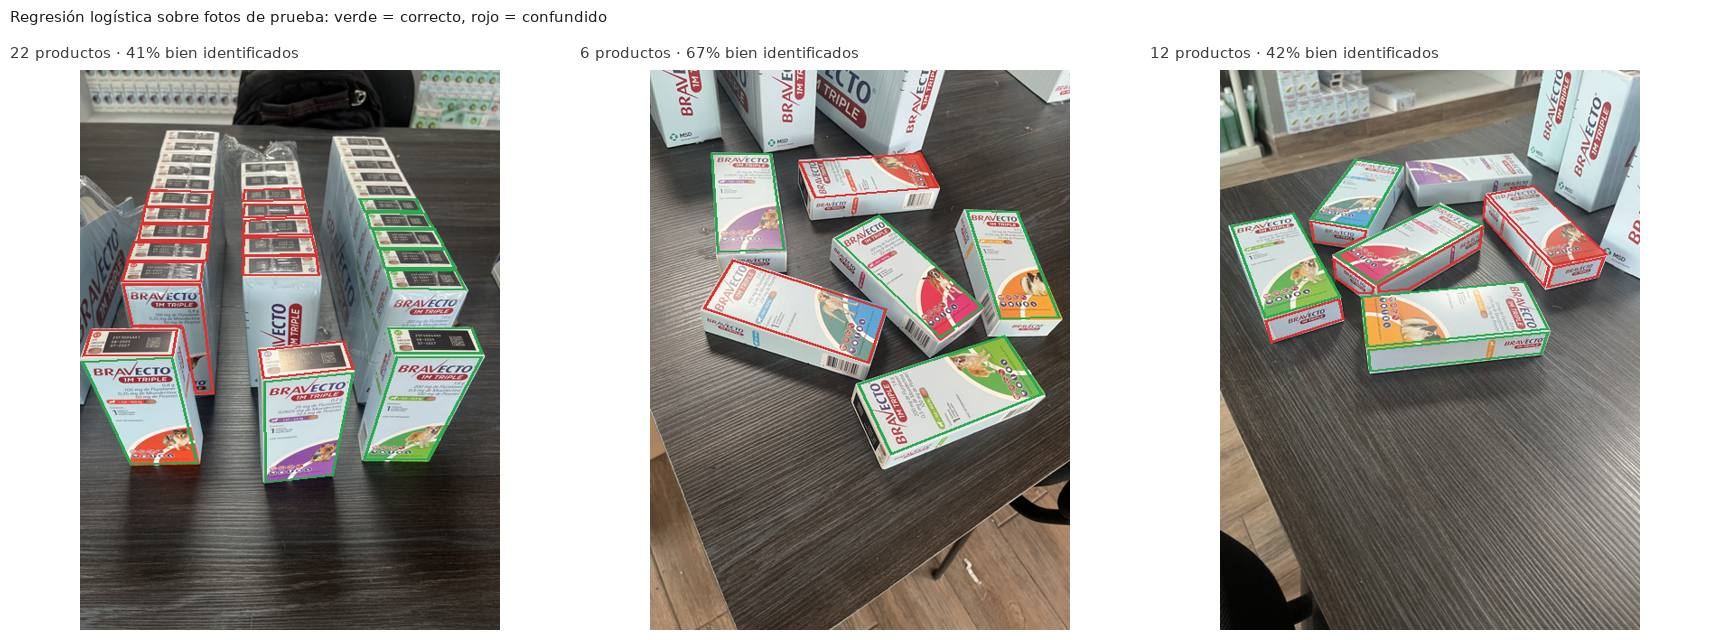

In [24]:
# Fotos de prueba con las predicciones del modelo final: verde = producto correcto, rojo = confundido.
test_df = df.iloc[test_idx].assign(pred=pred_final)
def draw_predictions(photo_name, max_side=620):
    with Image.open(PHOTO_PATH[photo_name]) as src:
        im = ImageOps.exif_transpose(src).convert("RGB")
    im.thumbnail((max_side, max_side)); W, H = im.size; d = ImageDraw.Draw(im)
    rows_ = test_df[test_df.foto == photo_name]
    for idx, r in rows_.iterrows():
        d.polygon([(x * W / 100, y * H / 100) for x, y in POLYS[idx]], outline=(40, 170, 80) if r.clase == r.pred else (220, 50, 50), width=3)
    return im, (rows_.clase == rows_.pred).mean(), len(rows_)
n_test_boxes = test_df.groupby("foto").size()
cands = n_test_boxes[(n_test_boxes >= 6) & (n_test_boxes <= 25)].index.tolist()[:3]
if cands:
    shots = [draw_predictions(name) for name in cands]
    show_mosaic([s[0] for s in shots], [f"{s[2]} productos · {s[1]:.0%} bien identificados" for s in shots], cols=len(cands), cell=560,
                title=f"{FINAL_NAME} sobre fotos de prueba: verde = correcto, rojo = confundido")

In [25]:
# Se guarda el modelo final y la tabla comparativa en carpetas locales del proyecto (no se publican en el repositorio).
out_dir = EXPORT_DIR.parent.parent
(out_dir / "03_modelos").mkdir(exist_ok=True); (out_dir / "04_resultados").mkdir(exist_ok=True)
joblib.dump({"modelo": FINAL, "algoritmo": FINAL_NAME, "representacion": FINAL_VIEW, "clases": list(FINAL.classes_)}, out_dir / "03_modelos" / "avance4_modelo_final.joblib")
stage1.to_csv(out_dir / "04_resultados" / "avance4_etapa1_comparativa.csv", index=False); cmp.to_csv(out_dir / "04_resultados" / "avance4_modelos_ajustados.csv")
print("Guardados:", "03_modelos/avance4_modelo_final.joblib · 04_resultados/avance4_etapa1_comparativa.csv · 04_resultados/avance4_modelos_ajustados.csv")

Guardados: 03_modelos/avance4_modelo_final.joblib · 04_resultados/avance4_etapa1_comparativa.csv · 04_resultados/avance4_modelos_ajustados.csv


## 11. Resumen y conclusiones

La celda siguiente imprime las cifras calculadas en esta ejecución; el texto posterior las interpreta.

In [26]:
print("RESUMEN — MODELOS ALTERNATIVOS")
print(f"- {len(MODELS)} algoritmos individuales × {len(VIEWS)} representaciones = {len(MODELS) * len(VIEWS)} configuraciones en validación cruzada agrupada por foto ({cv.n_splits} pliegues).")
b = stage1.iloc[0]; w = stage1.iloc[-1]
print(f"- Mejor configuración por defecto: {b.modelo} sobre {b['características']} (macro-F1 CV {b.macroF1_CV:.3f}); peor: {w.modelo} sobre {w['características']} ({w.macroF1_CV:.3f}).")
base_ref = pd.DataFrame(ref).set_index("modelo").loc["Referencia · Avance 3 (LR, C=0.3, A)", "macroF1_CV"]
print(f"- Baseline del Avance 3 en esta misma validación cruzada: {base_ref:.3f}.")
print("- Mejores por algoritmo (macro-F1 CV): " + "; ".join(f"{r.modelo} {r.macroF1_CV:.3f}" for _, r in best_per_model.iterrows()) + ".")
for m, (s, v) in searches.items():
    r = tune.loc[m]; print(f"- Ajuste fino · {m} ({v}): {r.macroF1_CV_defecto:.3f} → {r.macroF1_CV_ajustado:.3f} ({r.mejora:+.3f}) con {int(r.ajustes_totales)} ajustes en {r['t_búsqueda_s']:.0f} s.")
print(f"- Modelo final: {FINAL_NAME} sobre {FINAL_VIEW}; macro-F1 CV {cand.loc[FINAL_NAME, 'macroF1_CV']:.3f} ± {cand.loc[FINAL_NAME, 'desv_CV']:.3f}; prueba {final_row.macroF1_test:.3f} {final_row.IC95_macroF1_test}.")
print(f"- Prueba fija · Avance 3: macro-F1 {cmp.iloc[0].macroF1_test:.3f}, top-3 {cmp.iloc[0].top3_test:.3f}, línea {cmp.iloc[0].acc_línea_test:.3f}, marca {cmp.iloc[0].acc_marca_test:.3f}, conteos exactos {cmp.iloc[0].conteos_exactos:.1%}.")
print(f"- Prueba fija · final: macro-F1 {final_row.macroF1_test:.3f}, top-3 {final_row.top3_test:.3f}, línea {final_row.acc_línea_test:.3f}, marca {final_row.acc_marca_test:.3f}, conteos exactos {final_row.conteos_exactos:.1%}, error de conteo {final_row.error_conteo:.2f}.")
print(f"- Costo del final: entrenamiento {final_row.t_entren_s:.1f} s, inferencia {final_row.ms_por_1000_prod:.0f} ms por 1000 productos, tamaño {final_row['tamaño_KB']:.0f} KB; extractor CNN: {cand.loc[FINAL_NAME, 'extractor_CNN']} ({cand.loc[FINAL_NAME, 'extracción_ms_producto']:.0f} ms por producto en CPU).")

RESUMEN — MODELOS ALTERNATIVOS
- 8 algoritmos individuales × 5 representaciones = 40 configuraciones en validación cruzada agrupada por foto (5 pliegues).
- Mejor configuración por defecto: Regresión logística sobre E · A + D (860) (macro-F1 CV 0.530); peor: Árbol de decisión sobre D · ConvNeXt-T (768) (0.145).
- Baseline del Avance 3 en esta misma validación cruzada: 0.382.
- Mejores por algoritmo (macro-F1 CV): Regresión logística 0.530; Análisis discriminante (LDA) 0.513; SVM lineal 0.490; Red neuronal (MLP) 0.466; k vecinos (kNN) 0.345; SVM RBF 0.330; Naive Bayes gaussiano 0.264; Árbol de decisión 0.258.
- Ajuste fino · Regresión logística (E · A + D (860)): 0.530 → 0.544 (+0.013) con 700 ajustes en 47 s.
- Ajuste fino · Análisis discriminante (LDA) (E · A + D (860)): 0.513 → 0.518 (+0.004) con 700 ajustes en 13 s.
- Modelo final: Regresión logística sobre E · A + D (860); macro-F1 CV 0.544 ± 0.128; prueba 0.253 [0.210, 0.456].
- Prueba fija · Avance 3: macro-F1 0.169, top-3 0.404,

### 11.1 Respuestas a lo que pide el avance

**Modelos construidos y comparados.** Se entrenaron **8 algoritmos individuales** (regresión logística, SVM lineal, SVM RBF, k vecinos, árbol de decisión, Naive Bayes gaussiano, análisis discriminante lineal y red neuronal MLP) sobre **5 representaciones** de cada producto, es decir 40 configuraciones, con validación cruzada de 5 pliegues agrupada por foto sobre el conjunto de entrenamiento. La tabla de la sección 6 las ordena por macro-F1 e incluye *balanced accuracy*, top-3, exactitud por línea y tiempo de entrenamiento. La mejor configuración por defecto fue la regresión logística sobre E (0.530 ± 0.117) y la peor el árbol de decisión sobre D (0.145). El baseline del Avance 3, en esta misma validación, obtiene 0.382.

**¿Pesa más el algoritmo o la representación?** La representación. Con las 92 características a mano ningún algoritmo pasa de 0.38 (LDA 0.375, regresión logística 0.368, MLP 0.364). Al agregar *embeddings* de ConvNeXt-Tiny, la regresión logística sube a 0.530, el LDA a 0.513, la SVM lineal a 0.490 y el MLP a 0.466: de +0.10 a +0.16 de macro-F1. El extractor también importa: con MobileNetV3 (B) la regresión logística queda en 0.400. En cambio, concatenar las características a mano con el *embedding* (E frente a D) agrega solo ≈ 0.02 (0.511 → 0.530 en regresión logística), menos que la variación entre pliegues (≈ 0.12), así que esa ventaja no está demostrada.

**¿Qué familias funcionan?** Los modelos lineales regularizados (regresión logística, LDA, SVM lineal) y el MLP encabezan la comparación; k vecinos (0.345), SVM RBF (0.330), Naive Bayes (0.264) y el árbol de decisión (0.258) quedan claramente atrás. Con ≈ 12 productos por clase y cientos de variables, los modelos lineales generalizan mejor que los basados en distancias, densidades por variable o reglas. Este orden corresponde a hiperparámetros por defecto y solo los dos primeros se ajustaron; SVM RBF y k vecinos podrían mejorar con ajuste, aunque la distancia al primer lugar (≈ 0.19) es grande.

**Ajuste fino.** Los dos mejores fueron la regresión logística y el LDA, ambos sobre E. Cada uno se ajustó en dos rondas (80 + 60 configuraciones, 700 ajustes por modelo) sobre un espacio que incluye regularización (C o *shrinkage*), peso de clases y PCA (sin reducir o de 16 a 256 componentes). El resultado es modesto: la regresión logística pasó de 0.530 a 0.544 (+0.013) y el LDA de 0.513 a 0.518 (+0.004). Las gráficas de la sección 8.2 muestran que el espacio no es plano (una regularización excesiva, C < 0.01, o un PCA de 16 a 32 componentes rinden mucho peor), pero que su parte alta es una **meseta**: las cinco mejores configuraciones de cada modelo difieren en menos de 0.01 de macro-F1, muy por debajo de la desviación entre pliegues (≈ 0.12). Es decir, los valores por defecto ya estaban en la zona buena y lo que limita el rendimiento es la información de la representación y la escasez de ejemplos, no la regularización. El tamaño de entrada de la CNN (sección 8.1) tampoco ayuda: 320 px es el mejor para la regresión logística (0.511 frente a 0.466 con 224 px y 0.433 con 448 px) y equivalente para el LDA (0.494 frente a 0.497 y 0.468), por lo que se conserva. Como estas comparaciones usan las mismas validaciones cruzadas con las que se elige la configuración, la mejora medida es ligeramente optimista; aun así es mínima.

**Confirmación en la prueba (10 fotos, sin usarse antes).**

| | macro-F1 | top-3 | línea | marca | conteos exactos |
|---|---|---|---|---|---|
| Baseline Avance 3 | 0.169 | 0.404 | 0.565 | 0.913 | 9.3 % |
| Regresión logística ajustada | 0.253 | 0.472 | 0.602 | 0.944 | 16.7 % |
| LDA ajustado | 0.270 | 0.491 | 0.615 | 0.963 | 22.4 % |

Los dos modelos ajustados superan al baseline en todas las métricas de la tabla, en el mismo sentido que la validación cruzada (el error medio de conteo del LDA, 3.10 piezas, es la excepción: queda un poco por encima del 3.04 del baseline, mientras que el de la regresión logística baja a 2.86). Pero los intervalos de incertidumbre por *bootstrap* de fotos (sección 9) se traslapan, así que con solo 10 fotos de prueba no se puede afirmar que la mejora sea estadísticamente concluyente. Las señales más claras son el aumento de conteos exactos (de 9.3 % a 17–22 %) y de la exactitud de marca.

### 11.2 Modelo individual final

**Regresión logística (C ≈ 16, pesos de clase balanceados, PCA a 256 componentes) sobre las variables E: 92 características a mano + 768 valores de ConvNeXt-Tiny congelada.** Argumentos, más allá de la métrica principal:

1. **Desempeño y estabilidad.** Tiene el mayor macro-F1 en validación cruzada (0.544 ± 0.128). El LDA obtiene un macro-F1 algo mayor en prueba (0.270 frente a 0.253), pero la diferencia entre ambos es mucho menor que la incertidumbre (los intervalos se traslapan casi por completo) y apunta en sentido contrario al de la validación cruzada. Dado el empate técnico (regla de una desviación estándar), se prefiere el modelo más simple y estable.
2. **Interpretabilidad.** Los coeficientes por clase y variable permiten auditar qué rasgos usa el modelo y por qué se confunden dos presentaciones. En un contexto veterinario, donde un error de dosis tiene consecuencias, poder explicar la decisión importa.
3. **Probabilidades.** Entrega una probabilidad por clase, lo que permite fijar un umbral para marcar un producto como "desconocido" o enviarlo a revisión, y ofrecer sugerencias top-3 (0.472 en prueba) a un operador.
4. **Despliegue.** El clasificador es una multiplicación de matrices pequeña (≈ 1.8 MB; unos 8 ms por cada 1 000 productos), que incluso podría ejecutarse en un Worker. El costo real está en el extractor, no en el clasificador; el LDA pesa ≈ 5.9 MB y depende de la estimación de una covarianza de 860 × 860.
5. **Entrenamiento.** Tarda unos 13 s en CPU (frente a menos de 1 s del LDA), irrelevante porque se reentrena solo cuando llegan etiquetas nuevas.

**Costo y *trade-offs*.** ConvNeXt-Tiny tarda ≈ 0.28 s por producto en CPU (mediana medida en un Mac M2 sin GPU): unos 4.5 s para una foto con 16 productos (el promedio en prueba) y ≈ 2 s con la mediana de 7. MobileNetV3 cuesta ≈ 55 ms (en esta CPU ResNet-50 resultó incluso más rápido, ≈ 22 ms, con un desempeño similar: 0.423 con regresión logística) y las características a mano ≈ 6 ms, pero rinden menos (regresión logística: 0.440 sobre C y 0.368 sobre A). Como el uso previsto es "una foto → conteo" y no tiempo real, y el cálculo puede agruparse en lotes y acelerarse con GPU u ONNX, se acepta el costo del extractor grande. Si el sistema tuviera que correr solo en CPU de bajo costo, la alternativa razonable es una regresión logística sobre un extractor ligero (por ejemplo, sobre C con MobileNetV3, con ≈ 0.1 menos de macro-F1; ResNet-50 sería otra opción por su velocidad en esta CPU, pero no se evaluó combinado con las características a mano). La latencia con GPU u ONNX no se midió en este avance.

### 11.3 Limitaciones

- La prueba tiene solo 10 fotos (161 productos) y 3 clases que el entrenamiento nunca vio (14 productos que nadie podría acertar). Por eso su macro-F1 (0.25–0.27) es mucho menor que el de la validación cruzada (≈ 0.52–0.54) y debe leerse como un rango, no como un valor puntual.
- Nueve clases tienen menos de cinco ejemplos y una solo uno; su desempeño no es confiable.
- Los errores más frecuentes se concentran en viales de Nobivac que se confunden entre sí y en dosis de Bravecto, cuya diferencia está en el texto del empaque. Las representaciones no leen texto.
- Solo se ajustaron dos algoritmos y la CNN se usó congelada; no se probó ajustarla.
- La meta propuesta en el Avance 3 (macro-F1 ≥ 0.80 y ≥ 90 % de conteos exactos) sigue lejos: 0.54 en validación cruzada y 17 % de conteos exactos en prueba.

### 11.4 Siguientes pasos

1. **Ajustar la CNN de extremo a extremo** (*fine-tuning*) con aumento de datos, en GPU, y comparar con el modelo final de este avance usando la misma partición.
2. **Leer el texto del empaque** (dosis, número de tabletas) del frente de la caja.
3. **Clasificación jerárquica** marca → línea → presentación, aprovechando que la marca ya se identifica casi siempre (94 % en prueba).
4. **Detector de cajas + este clasificador** y evaluación del conteo de extremo a extremo.
5. Más etiquetas para las clases con menos de cinco ejemplos y una **política de conteo de pilas** acordada con el cliente.
6. Medir la latencia del extractor en GPU/ONNX para decidir dónde se despliega.

## Referencias

- Géron, A. (2022). *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* (3.ª ed.). O'Reilly Media. [O'Reilly](https://learning.oreilly.com/library/view/hands-on-machine-learning/9781098125967/). Cap. 2 (*Fine-Tune Your Model*) y capítulos 3–5, 7 y 10.
- Bergstra, J., & Bengio, Y. (2012). Random search for hyper-parameter optimization. *Journal of Machine Learning Research, 13*, 281–305.
- Howard, A. et al. (2019). Searching for MobileNetV3. *ICCV*.
- Visengeriyeva, L., Kammer, A., Bär, I., Kniesz, A., & Plöd, M. (2023). *CRISP-ML(Q): The ML Lifecycle Process*. [INNOQ](https://ml-ops.org/content/crisp-ml).
- Scikit-learn. [`RandomizedSearchCV`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RandomizedSearchCV.html), [`StratifiedGroupKFold`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html), [`cross_validate`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_validate.html).

# Declaración de uso de IA y contribución del equipo

### Uso de herramientas de IA

| Herramienta utilizada | Propósito de uso | Alcance del apoyo (celdas o secciones) | Responsabilidad: qué revisó o validó el equipo |
|---|---|---|---|
| Anthropic. (2026). Claude Code (Claude Sonnet 5.5) [Modelo de lenguaje grande]. https://claude.com/claude-code | Escribir y depurar el código de la comparación de modelos (extracción de características y *embeddings*, validación cruzada, búsqueda de hiperparámetros, gráficas); ejecutar el notebook; redactar borradores de las explicaciones y conclusiones | Código de las secciones 2 a 10 (incluidos los experimentos de las secciones 4.1 y 8.1) y borradores de los textos de las secciones 1 a 11 | Se ejecutó el notebook completo y se contrastó cada cifra citada en el texto con las salidas; se detectaron y corrigieron dos defectos (ajustes de la búsqueda de hiperparámetros que fallaban y se registraban como macro-F1 = 0, y tiempos de extracción inestables); se verificó que el conjunto de prueba no se usara para elegir modelos ni hiperparámetros |

### Contribución individual

| Integrante | Contribución al avance |
|---|---|
| Arnulfo Cavazos | Etiquetó en Label Studio las 23 fotografías de su carpeta; definió el caso de uso (identificar y contar productos por foto) y los alcances del avance; dirigió y revisó el trabajo realizado con la herramienta de IA y supervisó la ejecución del notebook. |
| Integrante 1 | Junto con el Integrante 2, etiquetó en Label Studio 120 etiquetas de productos, repartidas por mitades (60 cada uno), que alimentan los datos del proyecto. |
| Integrante 2 | Junto con el Integrante 1, etiquetó en Label Studio 120 etiquetas de productos, repartidas por mitades (60 cada uno), que alimentan los datos del proyecto. |

### Decisiones principales

<small>Las tres decisiones que más influyeron en el avance, con la alternativa que se descartó.</small>

<small><b>Decisión 1:</b> Particionar y validar por fotografía, no por producto</small>
- <small>Justificación: los productos de una misma foto comparten luz, ángulo, fondo y a veces son copias de la misma caja; agruparlos por foto en la validación cruzada y en la prueba evita que el modelo vea en entrenamiento productos casi idénticos a los de prueba.</small>
- <small>Alternativa descartada y motivo: una partición aleatoria por producto, porque produciría métricas artificialmente altas por fuga de información y no reflejaría el desempeño ante fotos nuevas.</small>

<small><b>Decisión 2:</b> Cambiar de representación tras ver los primeros resultados: de MobileNetV3 a ConvNeXt-Tiny</small>
- <small>Justificación: los primeros resultados mostraron que cambiar de algoritmo mejoraba poco frente a las 92 características a mano; se compararon cuatro extractores de CNN congelados (sección 4.1) y ConvNeXt-Tiny fue el más informativo (+0.09 a +0.11 de macro-F1 frente a MobileNetV3 con regresión logística y LDA), por lo que se incorporó como representación principal.</small>
- <small>Alternativa descartada y motivo: seguir solo con las características a mano o con MobileNetV3, porque su desempeño era claramente inferior; también se descartó afinar la CNN de extremo a extremo, porque requiere GPU y más datos de los disponibles.</small>

<small><b>Decisión 3:</b> Elegir la regresión logística como modelo final con la regla de una desviación estándar</small>
- <small>Justificación: la regresión logística y el LDA quedaron empatados dentro de una desviación estándar en validación cruzada y el LDA ganó por muy poco en una prueba de solo 10 fotos; se eligió la regresión logística por ser más simple, interpretable, ligera (≈ 1.8 MB frente a ≈ 5.9 MB), con probabilidades por clase y un macro-F1 promedio algo mayor en validación cruzada (0.544 frente a 0.518).</small>
- <small>Alternativa descartada y motivo: elegir el modelo con el mejor macro-F1 en la prueba (LDA), porque la diferencia está dentro de la incertidumbre y usar la prueba para decidir invalidaría su papel de confirmación independiente.</small>